In [ ]:

!pip -q install -U gdown

import gdown

folder_url = "https://drive.google.com/drive/folders/1qsjGWrgmEvOaf2Is2fh7RgVEkKd1V3df"

gdown.download_folder(
    url=folder_url,
    output="/content/volt_relay_data",
    quiet=False
)


Retrieving folder contents


Processing file 1ODkUSlw3EzpzznYdzZe74wG84t3783al batteries.csv
Processing file 1UMDldAGOUEJitZ32D4M9szwRMvUjZc4G city_daily_context.csv
Processing file 1fMy7LxZxESBqeveFB3iabpE3sxjnkkmY fleet_partners.csv
Processing file 1w3TxH3NY2rk_agikJtv3oCq2OeXv1Pii riders.csv
Processing file 1pbGACXY95BemIbrSlRxE6o8CGcc2bSCn station_hourly_status.csv
Processing file 1WEou9h5lYvALA3IreUFoCRbmIh2_9Dm2 stations.csv
Processing file 1tWK-zDoRy8QFqQe9ESw8ttpKHqMqMXbh support_tickets.csv
Processing file 15qkHruvAilomjWdNgntXrQLK4-_NPOZZ swap_events.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1ODkUSlw3EzpzznYdzZe74wG84t3783al
To: /content/volt_relay_data/batteries.csv
100%|██████████| 624k/624k [00:00<00:00, 7.71MB/s]
Downloading...
From: https://drive.google.com/uc?id=1UMDldAGOUEJitZ32D4M9szwRMvUjZc4G
To: /content/volt_relay_data/city_daily_context.csv
100%|██████████| 223k/223k [00:00<00:00, 4.74MB/s]
Downloading...
From: https://drive.google.com/uc?id=1fMy7LxZxESBqeveFB3iabpE3sxjnkkmY
To: /content/volt_relay_data/fleet_partners.csv
100%|██████████| 1.18k/1.18k [00:00<00:00, 3.47MB/s]
Downloading...
From: https://drive.google.com/uc?id=1w3TxH3NY2rk_agikJtv3oCq2OeXv1Pii
To: /content/volt_relay_data/riders.csv
100%|██████████| 2.10M/2.10M [00:00<00:00, 17.8MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1pbGACXY95BemIbrSlRxE6o8CGcc2bSCn
From (redirected): https://drive.google.com/uc?id=1pbGACXY95Bem

['/content/volt_relay_data/batteries.csv',
 '/content/volt_relay_data/city_daily_context.csv',
 '/content/volt_relay_data/fleet_partners.csv',
 '/content/volt_relay_data/riders.csv',
 '/content/volt_relay_data/station_hourly_status.csv',
 '/content/volt_relay_data/stations.csv',
 '/content/volt_relay_data/support_tickets.csv',
 '/content/volt_relay_data/swap_events.csv']

Load all datasets

In [ ]:

import pandas as pd
import os

folder = "/content/volt_relay_data"

# Load smaller datasets first
data = {}

small_files = [
    "batteries.csv",
    "city_daily_context.csv",
    "fleet_partners.csv",
    "riders.csv",
    "stations.csv",
    "support_tickets.csv"
]

for file in small_files:
    name = file.replace(".csv", "")
    data[name] = pd.read_csv(f"{folder}/{file}")
    print(f"{name}: {data[name].shape}")


batteries: (6500, 13)
city_daily_context: (3282, 12)
fleet_partners: (12, 12)
riders: (20000, 12)
stations: (152, 22)
support_tickets: (44000, 12)


Sepratelt inspects large datasets

In [ ]:

swap_sample = pd.read_csv(
    f"{folder}/swap_events.csv",
    nrows=5
)

station_sample = pd.read_csv(
    f"{folder}/station_hourly_status.csv",
    nrows=5
)

print("SWAP EVENTS")
display(swap_sample)

print("STATION HOURLY STATUS")
display(station_sample)


SWAP EVENTS


,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,...,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode
0,SW-000000001,RD-1000003,STN-MUM-115,2024-01-01 11:10:56,swap_completed,1,88,BAT-2W-103542,BAT-2W-102547,15.0,...,98.9,80.4,PARTNER,60.0,6.0,54.0,partner_invoice,2.035,v3.2.1,realtime
1,SW-000000002,RD-1000004,STN-HYD-070,2024-01-01 17:13:06,swap_completed,1,148,BAT-2W-105296,BAT-2W-101923,8.3,...,98.2,66.1,PARTNER,60.0,9.0,51.0,partner_invoice,2.157,v3.2.0,realtime
2,SW-000000003,RD-1000005,STN-DEL-046,2024-01-01 20:15:14,swap_completed,1,307,BAT-2W-104732,BAT-2W-102492,11.5,...,99.1,66.6,STD,60.0,0.0,60.0,partner_invoice,2.039,v3.2.0,realtime
3,SW-000000004,RD-1000006,STN-JAI-135,2024-01-01 20:26:07,swap_completed,1,399,BAT-2W-103839,BAT-2W-103267,7.9,...,98.2,65.4,STD,60.0,0.0,60.0,partner_invoice,2.194,v3.2.0,realtime
4,SW-000000005,RD-1000012,STN-PUN-100,2024-01-01 21:13:07,swap_completed,1,201,BAT-2W-104056,BAT-2W-106218,10.5,...,99.9,73.8,STD,60.0,0.0,60.0,partner_invoice,1.971,v3.2.1,realtime


STATION HOURLY STATUS


,station_id,hour_start,charged_2w_avg,charged_2w_min,charged_3w_min,packs_charging,packs_quarantined,chargers_online,ambient_temp_c,cabinet_temp_c,avg_charge_minutes,outage_minutes,grid_kwh,telemetry_status
0,STN-BLR-001,2024-01-01 00:00:00,6.29,6,4,1,0,18,8.2,13.5,92.6,0,1.86,ok
1,STN-BLR-001,2024-01-01 01:00:00,8.10,8,4,8,0,18,8.2,11.5,88.0,0,13.96,ok
2,STN-BLR-001,2024-01-01 02:00:00,10.56,8,4,5,0,18,8.2,12.9,80.2,0,8.27,ok
3,STN-BLR-001,2024-01-01 03:00:00,7.44,6,3,5,0,18,8.2,13.2,86.7,0,8.38,ok
4,STN-BLR-001,2024-01-01 04:00:00,9.18,7,3,3,0,18,8.2,14.0,83.9,0,4.28,ok


Overall Schemas

In [ ]:
for name, df in data.items():
    print("\n" + "="*60)
    print("DATASET:", name)
    print("ROWS & COLUMNS:", df.shape)
    print("COLUMNS:", df.columns.tolist())
    print("DATA TYPES:")
    print(df.dtypes)



DATASET: batteries
ROWS & COLUMNS: (6500, 13)
COLUMNS: ['battery_id', 'pack_type', 'supplier', 'manufacturing_lot', 'manufacture_date', 'commission_date', 'rated_capacity_kwh', 'purchase_cost_inr', 'initial_soh_pct', 'bms_firmware', 'retired_date', 'retirement_reason', 'current_soh_pct']
DATA TYPES:
battery_id             object
pack_type              object
supplier               object
manufacturing_lot      object
manufacture_date       object
commission_date        object
rated_capacity_kwh    float64
purchase_cost_inr       int64
initial_soh_pct       float64
bms_firmware           object
retired_date           object
retirement_reason      object
current_soh_pct       float64
dtype: object

DATASET: city_daily_context
ROWS & COLUMNS: (3282, 12)
COLUMNS: ['city', 'date', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'heat_alert', 'flood_disruption', 'festival_or_event', 'is_public_holiday', 'grid_outage_hours', 'competitor_promo_active', 'ecommerce_sale_event']
DATA TYPES:
city     

Installing DuckDB for large dataset handling

In [ ]:
import duckdb
import os

folder = "/content/volt_relay_data"
con = duckdb.connect()

tables = [
    "batteries",
    "city_daily_context",
    "fleet_partners",
    "riders",
    "stations",
    "support_tickets",
    "station_hourly_status",
    "swap_events"
]

for name in tables:
    path = os.path.join(folder, name + ".csv")

    try:
        con.execute(f"""
            CREATE OR REPLACE VIEW {name} AS
            SELECT * FROM read_csv(
                '{path}',
                delim=',',
                quote='"',
                escape='"',
                header=true,
                strict_mode=false,
                sample_size=-1
            )
        """)

        print(f"SUCCESS: {name}")

    except Exception as e:
        print(f"FAILED: {name}")
        print(str(e)[:1000])


SUCCESS: batteries
SUCCESS: city_daily_context
SUCCESS: fleet_partners
SUCCESS: riders
SUCCESS: stations
SUCCESS: support_tickets
SUCCESS: station_hourly_status
SUCCESS: swap_events


Data Profiling

In [ ]:

for name in tables:
    print("\n" + "="*60)
    print("DATASET:", name)

    result = con.execute(
        f"SELECT COUNT(*) FROM {name}"
    ).fetchone()[0]

    print("Total rows:", f"{result:,}")

    schema = con.execute(
        f"DESCRIBE {name}"
    ).df()

    print("\nColumns and data types:")
    display(schema)



DATASET: batteries
Total rows: 6,500

Columns and data types:


,column_name,column_type,null,key,default,extra
0,battery_id,VARCHAR,YES,None,None,None
1,pack_type,VARCHAR,YES,None,None,None
2,supplier,VARCHAR,YES,None,None,None
3,manufacturing_lot,VARCHAR,YES,None,None,None
4,manufacture_date,DATE,YES,None,None,None
5,commission_date,DATE,YES,None,None,None
6,rated_capacity_kwh,DOUBLE,YES,None,None,None
7,purchase_cost_inr,BIGINT,YES,None,None,None
8,initial_soh_pct,DOUBLE,YES,None,None,None
9,bms_firmware,VARCHAR,YES,None,None,None



DATASET: city_daily_context
Total rows: 3,282

Columns and data types:


,column_name,column_type,null,key,default,extra
0,city,VARCHAR,YES,None,None,None
1,date,DATE,YES,None,None,None
2,max_temp_c,DOUBLE,YES,None,None,None
3,min_temp_c,DOUBLE,YES,None,None,None
4,rainfall_mm,DOUBLE,YES,None,None,None
5,heat_alert,BOOLEAN,YES,None,None,None
6,flood_disruption,BOOLEAN,YES,None,None,None
7,festival_or_event,VARCHAR,YES,None,None,None
8,is_public_holiday,BOOLEAN,YES,None,None,None
9,grid_outage_hours,DOUBLE,YES,None,None,None



DATASET: fleet_partners
Total rows: 12

Columns and data types:


,column_name,column_type,null,key,default,extra
0,partner_id,VARCHAR,YES,None,None,None
1,partner_name,VARCHAR,YES,None,None,None
2,partner_segment,VARCHAR,YES,None,None,None
3,vehicle_class,VARCHAR,YES,None,None,None
4,contract_type,VARCHAR,YES,None,None,None
5,contract_start_date,DATE,YES,None,None,None
6,discount_pct,DOUBLE,YES,None,None,None
7,amendment_date,DATE,YES,None,None,None
8,discount_pct_after_amendment,DOUBLE,YES,None,None,None
9,peak_surcharge_billable,VARCHAR,YES,None,None,None


... (8 outputs left out)


DATASET: swap_events


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Total rows: 3,877,013

Columns and data types:


,column_name,column_type,null,key,default,extra
0,event_id,VARCHAR,YES,None,None,None
1,rider_id,VARCHAR,YES,None,None,None
2,station_id,VARCHAR,YES,None,None,None
3,event_ts,TIMESTAMP,YES,None,None,None
4,event_type,VARCHAR,YES,None,None,None
5,attempt_seq,BIGINT,YES,None,None,None
6,queue_wait_sec,BIGINT,YES,None,None,None
7,battery_in_id,VARCHAR,YES,None,None,None
8,battery_out_id,VARCHAR,YES,None,None,None
9,soc_in_pct,DOUBLE,YES,None,None,None


First audit event types and data range

In [ ]:

# 1. Swap event distribution
print("EVENT TYPES")
display(con.execute("""
    SELECT
        event_type,
        COUNT(*) AS total_events,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER(), 2) AS percentage
    FROM swap_events
    GROUP BY event_type
    ORDER BY total_events DESC
""").df())

# 2. Overall date range
print("\nSWAP EVENT DATE RANGE")
display(con.execute("""
    SELECT
        MIN(event_ts) AS first_event,
        MAX(event_ts) AS last_event,
        COUNT(*) AS total_records,
        COUNT(DISTINCT CAST(event_ts AS DATE)) AS active_dates
    FROM swap_events
""").df())

# 3. Other important categorical distributions
for table, column in [
    ("swap_events", "tariff_code"),
    ("swap_events", "payment_mode"),
    ("swap_events", "sync_mode"),
    ("support_tickets", "category"),
    ("support_tickets", "resolution_status"),
    ("batteries", "supplier"),
    ("batteries", "retirement_reason"),
    ("stations", "expansion_wave"),
    ("stations", "charger_generation"),
    ("fleet_partners", "partner_segment")
]:
    print(f"\n{table}.{column}")
    display(con.execute(f"""
        SELECT {column}, COUNT(*) AS total
        FROM {table}
        GROUP BY {column}
        ORDER BY total DESC
    """).df())


EVENT TYPES


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,total_events,percentage
0,swap_completed,3645809,94.04
1,failed_no_charged_battery,134389,3.47
2,abandoned_queue,68533,1.77
3,cancelled_by_rider,16712,0.43
4,failed_system_error,11570,0.30



SWAP EVENT DATE RANGE


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,first_event,last_event,total_records,active_dates
0,2024-01-01 00:00:33,2025-06-30 23:59:23,3877013,547


... (19 outputs left out)


stations.charger_generation


,charger_generation,total
0,Gen2,64
1,Gen1,51
2,Gen3,37



fleet_partners.partner_segment


,partner_segment,total
0,food_delivery,3
1,ecom_logistics,3
2,cargo_3w,2
3,quick_commerce,2
4,bike_taxi,2


In [ ]:

# A. Monthly operational performance
monthly = con.execute("""
    SELECT
        DATE_TRUNC('month', event_ts)::DATE AS month,
        COUNT(*) AS total_events,
        COUNT(*) FILTER (
            WHERE event_type = 'swap_completed'
        ) AS completed,
        COUNT(*) FILTER (
            WHERE event_type = 'failed_no_charged_battery'
        ) AS no_battery_failures,
        COUNT(*) FILTER (
            WHERE event_type = 'abandoned_queue'
        ) AS abandoned,
        COUNT(*) FILTER (
            WHERE event_type = 'failed_system_error'
        ) AS system_errors,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE event_type != 'swap_completed'
            ) / COUNT(*), 2
        ) AS unsuccessful_event_pct
    FROM swap_events
    GROUP BY 1
    ORDER BY 1
""").df()

display(monthly)

# B. Event ID uniqueness and missingness
print("\nEVENT ID INTEGRITY")
display(con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT event_id) AS unique_event_ids,
        COUNT(*) - COUNT(DISTINCT event_id) AS duplicate_id_excess,
        COUNT(*) FILTER (WHERE event_id IS NULL) AS null_event_ids
    FROM swap_events
""").df())

# C. Attempt sequence distribution
print("\nATTEMPT SEQUENCE")
display(con.execute("""
    SELECT
        event_type,
        attempt_seq,
        COUNT(*) AS total
    FROM swap_events
    GROUP BY event_type, attempt_seq
    ORDER BY event_type, attempt_seq
""").df())

# D. Check whether rider/station references exist
print("\nREFERENCE INTEGRITY")
display(con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE r.rider_id IS NULL
        ) AS unmatched_riders,
        COUNT(*) FILTER (
            WHERE s.station_id IS NULL
        ) AS unmatched_stations,
        COUNT(*) AS total_events
    FROM swap_events e
    LEFT JOIN riders r ON e.rider_id = r.rider_id
    LEFT JOIN stations s ON e.station_id = s.station_id
""").df())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,total_events,completed,no_battery_failures,abandoned,system_errors,unsuccessful_event_pct
0,2024-01-01,110348,105490,2690,1405,318,4.40
1,2024-02-01,111531,106582,2681,1451,346,4.44
2,2024-03-01,123900,118444,2938,1575,394,4.40
3,2024-04-01,131818,122836,5382,2683,393,6.81
4,2024-05-01,146278,128328,11313,5520,447,12.27
5,2024-06-01,148888,133743,9452,4596,459,10.17
6,2024-07-01,158688,151824,3734,2025,452,4.33
7,2024-08-01,172295,164931,3955,2185,469,4.27
8,2024-09-01,195885,187302,4690,2442,621,4.38
9,2024-10-01,229901,219838,5483,2904,665,4.38



EVENT ID INTEGRITY


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,unique_event_ids,duplicate_id_excess,null_event_ids
0,3877013,3877013,0,0



ATTEMPT SEQUENCE


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,attempt_seq,total
0,abandoned_queue,1,68533
1,cancelled_by_rider,1,16712
2,failed_no_charged_battery,1,134389
3,failed_system_error,1,11570
4,swap_completed,1,3645809



REFERENCE INTEGRITY


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,unmatched_riders,unmatched_stations,total_events
0,0,0,3877013


missing value check

In [ ]:

tables = [
    "swap_events",
    "station_hourly_status",
    "support_tickets",
    "riders",
    "batteries",
    "city_daily_context",
    "stations",
    "fleet_partners"
]

for table in tables:
    print(f"\n{'='*50}")
    print("DATASET:", table)

    columns = con.execute(
        f"DESCRIBE {table}"
    ).df()["column_name"].tolist()

    checks = ", ".join([
        f"COUNT(*) FILTER (WHERE \"{col}\" IS NULL) AS \"{col}\""
        for col in columns
    ])

    result = con.execute(
        f"SELECT {checks} FROM {table}"
    ).df()

    missing = result.T.reset_index()
    missing.columns = ["column", "missing_count"]
    missing["missing_percentage"] = (
        missing["missing_count"] /
        con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0] * 100
    ).round(2)

    display(
        missing[missing["missing_count"] > 0]
        .sort_values("missing_percentage", ascending=False)
    )



DATASET: swap_events


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column,missing_count,missing_percentage
8,battery_out_id,231204,5.96
19,energy_to_recharge_kwh,231204,5.96
12,soh_out_pct,231204,5.96
11,soc_out_pct,231204,5.96
10,soh_in_pct,28282,0.73
9,soc_in_pct,28282,0.73
7,battery_in_id,28282,0.73
13,km_since_last_swap,28282,0.73



DATASET: station_hourly_status


,column,missing_count,missing_percentage
4,charged_3w_min,821808,55.24
2,charged_2w_avg,9384,0.63
3,charged_2w_min,9384,0.63
5,packs_charging,9384,0.63
6,packs_quarantined,9384,0.63
8,ambient_temp_c,9384,0.63
9,cabinet_temp_c,9384,0.63
10,avg_charge_minutes,9384,0.63
12,grid_kwh,9384,0.63


... (8 outputs left out)


DATASET: stations


,column,missing_count,missing_percentage
8,decommissioned_date,151,99.34
21,competitor_within_1_5km_since,142,93.42



DATASET: fleet_partners


,column,missing_count,missing_percentage
7,amendment_date,11,91.67
8,discount_pct_after_amendment,11,91.67


Check 1: Failure events and missing battery values

In [ ]:

display(con.execute("""
    SELECT
        event_type,
        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE battery_out_id IS NULL
        ) AS missing_output_battery,

        COUNT(*) FILTER (
            WHERE battery_in_id IS NULL
        ) AS missing_input_battery,

        COUNT(*) FILTER (
            WHERE energy_to_recharge_kwh IS NULL
        ) AS missing_energy,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE battery_out_id IS NULL
            ) / COUNT(*), 2
        ) AS missing_output_pct

    FROM swap_events
    GROUP BY event_type
    ORDER BY total_events DESC
""").df())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,total_events,missing_output_battery,missing_input_battery,missing_energy,missing_output_pct
0,swap_completed,3645809,0,0,0,0.0
1,failed_no_charged_battery,134389,134389,0,134389,100.0
2,abandoned_queue,68533,68533,0,68533,100.0
3,cancelled_by_rider,16712,16712,16712,16712,100.0
4,failed_system_error,11570,11570,11570,11570,100.0


check 2: Missing values in 3W Charging data


In [ ]:

display(con.execute("""
    SELECT
        CASE
            WHEN s.slots_3w = 0 THEN 'No 3W slots'
            WHEN s.slots_3w > 0 THEN 'Has 3W slots'
            ELSE 'Unknown station'
        END AS station_3w_capacity,

        COUNT(*) AS total_hourly_records,

        COUNT(*) FILTER (
            WHERE h.charged_3w_min IS NULL
        ) AS missing_3w_records,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE h.charged_3w_min IS NULL
            ) / COUNT(*), 2
        ) AS missing_pct

    FROM station_hourly_status h
    LEFT JOIN stations s
        ON h.station_id = s.station_id
    GROUP BY 1
    ORDER BY 1
""").df())


,station_3w_capacity,total_hourly_records,missing_3w_records,missing_pct
0,Has 3W slots,669552,3648,0.54
1,No 3W slots,818160,818160,100.00


Check 3: Support tickets mein missing resolution time

In [ ]:

display(con.execute("""
    SELECT
        resolution_status,
        COUNT(*) AS total_tickets,

        COUNT(*) FILTER (
            WHERE resolution_hours IS NULL
        ) AS missing_resolution_hours,

        COUNT(*) FILTER (
            WHERE csat_score IS NULL
        ) AS missing_csat,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE resolution_hours IS NULL
            ) / COUNT(*), 2
        ) AS missing_resolution_pct

    FROM support_tickets
    GROUP BY resolution_status
    ORDER BY total_tickets DESC
""").df())


,resolution_status,total_tickets,missing_resolution_hours,missing_csat,missing_resolution_pct
0,resolved,37888,0,22759,0.0
1,unresolved,5175,5175,5175,100.0
2,duplicate,937,937,937,100.0


Check 4: Riders ke missing partner IDs

In [ ]:

display(con.execute("""
    SELECT
        DATE_TRUNC('month', signup_date)::DATE AS signup_month,
        COUNT(*) AS total_riders,

        COUNT(*) FILTER (
            WHERE partner_id IS NULL
        ) AS missing_partner,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE partner_id IS NULL
            ) / COUNT(*), 2
        ) AS missing_partner_pct

    FROM riders
    GROUP BY 1
    ORDER BY 1
""").df())


,signup_month,total_riders,missing_partner,missing_partner_pct
0,2023-03-01,323,114,35.29
1,2023-04-01,406,145,35.71
2,2023-05-01,367,124,33.79
3,2023-06-01,427,149,34.89
4,2023-07-01,388,153,39.43
5,2023-08-01,435,175,40.23
6,2023-09-01,433,144,33.26
7,2023-10-01,392,153,39.03
8,2023-11-01,405,180,44.44
9,2023-12-01,24,5,20.83


additional checking: For missing riders


In [ ]:

# Compare riders with and without partner IDs

display(con.execute("""
    SELECT
        CASE
            WHEN r.partner_id IS NULL
                THEN 'Missing partner ID'
            ELSE 'Partner ID available'
        END AS partner_status,

        COUNT(DISTINCT r.rider_id) AS total_riders,

        COUNT(DISTINCT e.rider_id) AS riders_with_events,

        COUNT(e.event_id) AS total_events,

        COUNT(*) FILTER (
            WHERE e.event_type = 'swap_completed'
        ) AS completed_swaps

    FROM riders r
    LEFT JOIN swap_events e
        ON r.rider_id = e.rider_id

    GROUP BY 1
    ORDER BY 1
""").df())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,partner_status,total_riders,riders_with_events,total_events,completed_swaps
0,Missing partner ID,7628,7602,1311535,1235968
1,Partner ID available,12372,12348,2565478,2409841


Which type of riders are missing

In [ ]:
display(con.execute("""
WITH rider_activity AS (
    SELECT
        rider_id,
        COUNT(event_id) AS total_events,
        COUNT(event_id) FILTER (
            WHERE event_type = 'swap_completed'
        ) AS completed_swaps
    FROM swap_events
    GROUP BY rider_id
)
SELECT
    CASE
        WHEN r.partner_id IS NULL
            THEN 'Missing partner ID'
        ELSE 'Partner ID available'
    END AS partner_status,
    r.home_city,
    r.plan_type,
    COUNT(*) AS total_riders,
    SUM(COALESCE(a.total_events, 0)) AS total_events,
    SUM(COALESCE(a.completed_swaps, 0)) AS completed_swaps
FROM riders r
LEFT JOIN rider_activity a
    ON r.rider_id = a.rider_id
GROUP BY 1, 2, 3
ORDER BY r.home_city, r.plan_type, partner_status
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,partner_status,home_city,plan_type,total_riders,total_events,completed_swaps
0,Partner ID available,BLR,partner_billed,38,7809.0,7451.0
1,Missing partner ID,BLR,pay_as_you_go,10,1712.0,1648.0
2,Missing partner ID,BLR,prepaid_pack,5,621.0,598.0
3,Partner ID available,Bangalore,partner_billed,18,4660.0,4472.0
4,Missing partner ID,Bangalore,pay_as_you_go,12,2033.0,1960.0
...,...,...,...,...,...,...
56,Missing partner ID,jaipur,pay_as_you_go,4,670.0,609.0
57,Missing partner ID,jaipur,prepaid_pack,4,579.0,526.0
58,Partner ID available,pune,partner_billed,21,4583.0,4344.0
59,Missing partner ID,pune,pay_as_you_go,13,2556.0,2433.0


Next check: Eaxct relationship b/w partner ID aur plan type

In [ ]:
display(con.execute("""
SELECT
    plan_type,
    CASE
        WHEN partner_id IS NULL THEN 'Missing partner ID'
        ELSE 'Partner ID available'
    END AS partner_status,
    COUNT(*) AS total_riders,
    ROUND(
        100.0 * COUNT(*) / SUM(COUNT(*)) OVER (
            PARTITION BY plan_type
        ), 2
    ) AS percentage_within_plan
FROM riders
GROUP BY plan_type, partner_status
ORDER BY plan_type, partner_status
""").df())

,plan_type,partner_status,total_riders,percentage_within_plan
0,partner_billed,Partner ID available,12372,100.0
1,pay_as_you_go,Missing partner ID,5299,100.0
2,prepaid_pack,Missing partner ID,2329,100.0


Checking Datatypes and duplicates ids

In [ ]:
tables = {
    "riders": ("riders", "rider_id"),
    "stations": ("stations", "station_id"),
    "batteries": ("batteries", "battery_id"),
    "support_tickets": ("support_tickets", "ticket_id"),
    "fleet_partners": ("fleet_partners", "partner_id")
}

for label, (table, key) in tables.items():
    result = con.execute(f"""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT {key}) AS unique_ids,
            COUNT(*) - COUNT(DISTINCT {key}) AS duplicate_or_null_ids,
            COUNT(*) FILTER (WHERE {key} IS NULL) AS null_ids
        FROM {table}
    """).df()

    print(f"\\n{label}")
    display(result)

\nriders


,total_rows,unique_ids,duplicate_or_null_ids,null_ids
0,20000,20000,0,0


\nstations


,total_rows,unique_ids,duplicate_or_null_ids,null_ids
0,152,152,0,0


\nbatteries


,total_rows,unique_ids,duplicate_or_null_ids,null_ids
0,6500,6500,0,0


\nsupport_tickets


,total_rows,unique_ids,duplicate_or_null_ids,null_ids
0,44000,44000,0,0


\nfleet_partners


,total_rows,unique_ids,duplicate_or_null_ids,null_ids
0,12,12,0,0


In [ ]:
display(con.execute("""
SELECT
    COUNT(*) AS total_rows,

    COUNT(*) FILTER (
        WHERE soc_in_pct < 0 OR soc_in_pct > 100
    ) AS invalid_soc_in,

    COUNT(*) FILTER (
        WHERE soc_out_pct < 0 OR soc_out_pct > 100
    ) AS invalid_soc_out,

    COUNT(*) FILTER (
        WHERE soh_in_pct < 0 OR soh_in_pct > 100
    ) AS invalid_soh_in,

    COUNT(*) FILTER (
        WHERE soh_out_pct < 0 OR soh_out_pct > 100
    ) AS invalid_soh_out,

    COUNT(*) FILTER (
        WHERE queue_wait_sec < 0
    ) AS negative_queue_wait,

    COUNT(*) FILTER (
        WHERE km_since_last_swap < 0
    ) AS negative_distance,

    COUNT(*) FILTER (
        WHERE list_price_inr < 0
    ) AS negative_list_price,

    COUNT(*) FILTER (
        WHERE discount_inr < 0
    ) AS negative_discount,

    COUNT(*) FILTER (
        WHERE amount_charged_inr < 0
    ) AS negative_amount,

    COUNT(*) FILTER (
        WHERE energy_to_recharge_kwh < 0
    ) AS negative_energy

FROM swap_events
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,invalid_soc_in,invalid_soc_out,invalid_soh_in,invalid_soh_out,negative_queue_wait,negative_distance,negative_list_price,negative_discount,negative_amount,negative_energy
0,3877013,0,3698,3356,2799,0,7814,0,0,0,0


Next check: whic event type has invalid values

In [ ]:
display(con.execute("""
SELECT
    event_type,
    COUNT(*) AS total_events,

    COUNT(*) FILTER (
        WHERE soc_out_pct < 0 OR soc_out_pct > 100
    ) AS invalid_soc_out,

    COUNT(*) FILTER (
        WHERE soh_in_pct < 0 OR soh_in_pct > 100
    ) AS invalid_soh_in,

    COUNT(*) FILTER (
        WHERE soh_out_pct < 0 OR soh_out_pct > 100
    ) AS invalid_soh_out,

    COUNT(*) FILTER (
        WHERE km_since_last_swap < 0
    ) AS negative_distance,

    MIN(soc_out_pct) FILTER (
        WHERE soc_out_pct < 0 OR soc_out_pct > 100
    ) AS min_invalid_soc_out,

    MAX(soc_out_pct) FILTER (
        WHERE soc_out_pct < 0 OR soc_out_pct > 100
    ) AS max_invalid_soc_out,

    MIN(soh_in_pct) FILTER (
        WHERE soh_in_pct < 0 OR soh_in_pct > 100
    ) AS min_invalid_soh_in,

    MAX(soh_in_pct) FILTER (
        WHERE soh_in_pct < 0 OR soh_in_pct > 100
    ) AS max_invalid_soh_in

FROM swap_events
GROUP BY event_type
ORDER BY event_type
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,total_events,invalid_soc_out,invalid_soh_in,invalid_soh_out,negative_distance,min_invalid_soc_out,max_invalid_soc_out,min_invalid_soh_in,max_invalid_soh_in
0,abandoned_queue,68533,0,44,0,139,NaN,NaN,100.1,100.8
1,cancelled_by_rider,16712,0,0,0,0,NaN,NaN,NaN,NaN
2,failed_no_charged_battery,134389,0,86,0,279,NaN,NaN,100.1,100.8
3,failed_system_error,11570,0,0,0,0,NaN,NaN,NaN,NaN
4,swap_completed,3645809,3698,3226,2799,7396,100.5,103.0,100.1,101.4


In [ ]:
display(con.execute("""
SELECT
    event_type,

    MIN(soh_out_pct) FILTER (
        WHERE soh_out_pct < 0 OR soh_out_pct > 100
    ) AS min_invalid_soh_out,

    MAX(soh_out_pct) FILTER (
        WHERE soh_out_pct < 0 OR soh_out_pct > 100
    ) AS max_invalid_soh_out,

    MIN(km_since_last_swap) FILTER (
        WHERE km_since_last_swap < 0
    ) AS min_negative_distance,

    MAX(km_since_last_swap) FILTER (
        WHERE km_since_last_swap < 0
    ) AS max_negative_distance,

    COUNT(*) FILTER (
        WHERE soh_out_pct < 0 OR soh_out_pct > 100
    ) AS invalid_soh_out_count,

    COUNT(*) FILTER (
        WHERE km_since_last_swap < 0
    ) AS negative_distance_count

FROM swap_events
GROUP BY event_type
ORDER BY event_type
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,min_invalid_soh_out,max_invalid_soh_out,min_negative_distance,max_negative_distance,invalid_soh_out_count,negative_distance_count
0,abandoned_queue,NaN,NaN,-20.0,-1.6,0,139
1,cancelled_by_rider,NaN,NaN,NaN,NaN,0,0
2,failed_no_charged_battery,NaN,NaN,-20.0,-1.0,0,279
3,failed_system_error,NaN,NaN,NaN,NaN,0,0
4,swap_completed,100.1,101.3,-20.0,-1.0,2799,7396


For checking each record has multiple errors

In [ ]:
display(con.execute("""
SELECT
    event_type,
    COUNT(*) AS total_events,

    COUNT(*) FILTER (
        WHERE soc_out_pct < 0 OR soc_out_pct > 100
           OR soh_in_pct < 0 OR soh_in_pct > 100
           OR soh_out_pct < 0 OR soh_out_pct > 100
           OR km_since_last_swap < 0
    ) AS events_with_any_invalid_value,

    COUNT(*) FILTER (
        WHERE
            (soc_out_pct < 0 OR soc_out_pct > 100)
            AND
            (soh_in_pct < 0 OR soh_in_pct > 100)
    ) AS invalid_soc_and_soh_in,

    COUNT(*) FILTER (
        WHERE
            (soh_out_pct < 0 OR soh_out_pct > 100)
            AND km_since_last_swap < 0
    ) AS invalid_soh_out_and_distance,

    COUNT(*) FILTER (
        WHERE
            (soc_out_pct < 0 OR soc_out_pct > 100)
            AND km_since_last_swap < 0
    ) AS invalid_soc_and_distance

FROM swap_events
GROUP BY event_type
ORDER BY event_type
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,total_events,events_with_any_invalid_value,invalid_soc_and_soh_in,invalid_soh_out_and_distance,invalid_soc_and_distance
0,abandoned_queue,68533,183,0,0,0
1,cancelled_by_rider,16712,0,0,0,0
2,failed_no_charged_battery,134389,365,0,0,0
3,failed_system_error,11570,0,0,0,0
4,swap_completed,3645809,17009,2,5,4


In [ ]:
display(con.execute("""
SELECT
    sync_mode,
    station_firmware,
    COUNT(*) AS total_events,

    COUNT(*) FILTER (
        WHERE soc_out_pct < 0 OR soc_out_pct > 100
           OR soh_in_pct < 0 OR soh_in_pct > 100
           OR soh_out_pct < 0 OR soh_out_pct > 100
           OR km_since_last_swap < 0
    ) AS affected_events,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE soc_out_pct < 0 OR soc_out_pct > 100
               OR soh_in_pct < 0 OR soh_in_pct > 100
               OR soh_out_pct < 0 OR soh_out_pct > 100
               OR km_since_last_swap < 0
        ) / COUNT(*), 3
    ) AS affected_pct

FROM swap_events
GROUP BY sync_mode, station_firmware
ORDER BY affected_pct DESC
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,sync_mode,station_firmware,total_events,affected_events,affected_pct
0,realtime,v3.2.0,1338213,6219,0.465
1,offline_batch,v3.2.1,368153,1664,0.452
2,offline_batch,v3.2.0,222961,1004,0.450
3,realtime,v3.2.1,1947686,8670,0.445


Dates and event timestamps

In [ ]:
display(con.execute("""
SELECT
    MIN(event_ts) AS earliest_event,
    MAX(event_ts) AS latest_event,
    COUNT(*) AS total_events,
    COUNT(*) FILTER (
        WHERE event_ts IS NULL
    ) AS missing_timestamps,
    COUNT(*) FILTER (
        WHERE TRY_CAST(event_ts AS TIMESTAMP) IS NULL
    ) AS invalid_timestamps
FROM swap_events
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,earliest_event,latest_event,total_events,missing_timestamps,invalid_timestamps
0,2024-01-01 00:00:33,2025-06-30 23:59:23,3877013,0,0


Signup date vs swap event date

In [ ]:
display(con.execute("""
SELECT
    COUNT(*) AS total_events,

    COUNT(*) FILTER (
        WHERE r.rider_id IS NULL
    ) AS events_without_matching_rider,

    COUNT(*) FILTER (
        WHERE r.signup_date IS NULL
    ) AS events_with_missing_signup_date,

    COUNT(*) FILTER (
        WHERE r.signup_date > CAST(e.event_ts AS DATE)
    ) AS events_before_signup,

    COUNT(DISTINCT e.rider_id) FILTER (
        WHERE r.signup_date > CAST(e.event_ts AS DATE)
    ) AS riders_with_events_before_signup

FROM swap_events e
LEFT JOIN riders r
    ON e.rider_id = r.rider_id
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events,events_without_matching_rider,events_with_missing_signup_date,events_before_signup,riders_with_events_before_signup
0,3877013,0,0,6,6


Inspection of that 6 records

In [ ]:
display(con.execute("""
SELECT
    e.event_id,
    e.rider_id,
    r.signup_date,
    e.event_ts,
    e.event_type,
    e.station_id,
    r.home_city,
    r.plan_type
FROM swap_events e
JOIN riders r
    ON e.rider_id = r.rider_id
WHERE r.signup_date > CAST(e.event_ts AS DATE)
ORDER BY e.event_ts
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_id,rider_id,signup_date,event_ts,event_type,station_id,home_city,plan_type
0,SW-002709969,RD-1015771,2025-03-13,2025-03-12 21:59:39,swap_completed,STN-JAI-148,Jaipur,pay_as_you_go
1,SW-002775821,RD-1015997,2025-03-20,2025-03-19 20:24:09,swap_completed,STN-MUM-117,Mumbai,partner_billed
2,SW-002835709,RD-1016172,2025-03-26,2025-03-25 23:54:40,swap_completed,STN-JAI-148,Jaipur,pay_as_you_go
3,SW-002855536,RD-1016223,2025-03-28,2025-03-27 20:18:15,swap_completed,STN-MUM-129,Mumbai,partner_billed
4,SW-002855543,RD-1016236,2025-03-28,2025-03-27 23:24:07,swap_completed,STN-MUM-117,Mumbai,partner_billed
5,SW-002999749,RD-1016731,2025-04-11,2025-04-10 20:41:19,swap_completed,STN-PUN-105,Pune,partner_billed


In [ ]:
con.execute("""
CREATE OR REPLACE VIEW swap_events_flagged AS
SELECT
    e.*,
    CASE
        WHEN r.rider_id IS NULL THEN 'missing_rider'
        WHEN r.signup_date > CAST(e.event_ts AS DATE)
            THEN 'event_before_signup'
        ELSE 'valid'
    END AS signup_date_status
FROM swap_events e
LEFT JOIN riders r
    ON e.rider_id = r.rider_id
""")

In [ ]:
display(con.execute("""
SELECT
    signup_date_status,
    COUNT(*) AS total_events
FROM swap_events_flagged
GROUP BY signup_date_status
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,signup_date_status,total_events
0,valid,3877007
1,event_before_signup,6


Start commsion date vs event date

In [ ]:
display(con.execute("""
SELECT
    COUNT(*) AS total_events,

    COUNT(*) FILTER (
        WHERE s.station_id IS NULL
    ) AS events_without_matching_station,

    COUNT(*) FILTER (
        WHERE s.commissioned_date IS NULL
    ) AS events_with_missing_commission_date,

    COUNT(*) FILTER (
        WHERE CAST(e.event_ts AS DATE) < s.commissioned_date
    ) AS events_before_commissioning,

    COUNT(*) FILTER (
        WHERE s.decommissioned_date IS NOT NULL
          AND CAST(e.event_ts AS DATE) > s.decommissioned_date
    ) AS events_after_decommissioning

FROM swap_events e
LEFT JOIN stations s
    ON e.station_id = s.station_id
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events,events_without_matching_station,events_with_missing_commission_date,events_before_commissioning,events_after_decommissioning
0,3877013,0,0,24,0


#Inspection of that 24 records

In [ ]:
display(con.execute("""
SELECT
    e.event_id,
    e.station_id,
    s.city,
    s.zone,
    s.commissioned_date,
    e.event_ts,
    e.event_type,
    s.expansion_wave,
    s.charger_generation
FROM swap_events e
JOIN stations s
    ON e.station_id = s.station_id
WHERE CAST(e.event_ts AS DATE) < s.commissioned_date
ORDER BY e.station_id, e.event_ts
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_id,station_id,city,zone,commissioned_date,event_ts,event_type,expansion_wave,charger_generation
0,SW-002827580,STN-BLR-031,Bengaluru,BLR-East,2025-03-26,2025-03-25 19:44:19,swap_completed,Wave2_2025H1,Gen3
1,SW-002834813,STN-BLR-031,Bengaluru,BLR-East,2025-03-26,2025-03-25 21:41:36,swap_completed,Wave2_2025H1,Gen3
2,SW-002725953,STN-HYD-087,Hyderabad,HYD-West,2025-03-15,2025-03-14 19:00:40,failed_system_error,Wave2_2025H1,Gen3
3,SW-002718703,STN-HYD-087,Hyderabad,HYD-West,2025-03-15,2025-03-14 20:35:18,swap_completed,Wave2_2025H1,Gen3
4,SW-002718638,STN-HYD-087,Hyderabad,HYD-West,2025-03-15,2025-03-14 22:18:01,swap_completed,Wave2_2025H1,Gen3
5,SW-002990211,STN-HYD-088,Hyderabad,HYD-West,2025-04-11,2025-04-10 19:05:31,swap_completed,Wave2_2025H1,Gen3
6,SW-002990397,STN-HYD-088,Hyderabad,HYD-West,2025-04-11,2025-04-10 20:45:15,swap_completed,Wave2_2025H1,Gen3
7,SW-002996743,STN-HYD-088,Hyderabad,HYD-West,2025-04-11,2025-04-10 22:33:30,swap_completed,Wave2_2025H1,Gen3
8,SW-002993312,STN-HYD-088,Hyderabad,HYD-West,2025-04-11,2025-04-10 23:12:01,swap_completed,Wave2_2025H1,Gen3
9,SW-003016718,STN-MUM-128,Mumbai,MUM-Andheri,2025-04-13,2025-04-12 20:46:21,swap_completed,Wave2_2025H1,Gen3


Is 24 events equally distributes in 8 stations

In [ ]:
display(con.execute("""
SELECT
    e.station_id,
    s.city,
    s.commissioned_date,
    COUNT(*) AS pre_commission_events,
    COUNT(*) FILTER (
        WHERE e.event_type = 'swap_completed'
    ) AS completed_swaps,
    COUNT(*) FILTER (
        WHERE e.event_type <> 'swap_completed'
    ) AS unsuccessful_events,
    MIN(e.event_ts) AS first_event,
    MAX(e.event_ts) AS last_event
FROM swap_events e
JOIN stations s
    ON e.station_id = s.station_id
WHERE CAST(e.event_ts AS DATE) < s.commissioned_date
GROUP BY
    e.station_id,
    s.city,
    s.commissioned_date
ORDER BY pre_commission_events DESC
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,station_id,city,commissioned_date,pre_commission_events,completed_swaps,unsuccessful_events,first_event,last_event
0,STN-PUN-109,Pune,2025-04-08,6,6,0,2025-04-07 18:52:18,2025-04-07 23:05:36
1,STN-MUM-129,Mumbai,2025-03-26,4,3,1,2025-03-25 19:36:35,2025-03-25 23:50:17
2,STN-HYD-088,Hyderabad,2025-04-11,4,4,0,2025-04-10 19:05:31,2025-04-10 23:12:01
3,STN-HYD-087,Hyderabad,2025-03-15,3,2,1,2025-03-14 19:00:40,2025-03-14 22:18:01
4,STN-MUM-130,Mumbai,2025-04-14,3,3,0,2025-04-13 21:33:58,2025-04-13 23:36:03
5,STN-BLR-031,Bengaluru,2025-03-26,2,2,0,2025-03-25 19:44:19,2025-03-25 21:41:36
6,STN-MUM-128,Mumbai,2025-04-13,2,2,0,2025-04-12 20:46:21,2025-04-12 23:23:46


merge all quality issues


In [ ]:
con.execute("""
CREATE OR REPLACE VIEW swap_events_quality_flags AS
SELECT
    e.*,

    -- Rider signup date check
    CASE
        WHEN r.rider_id IS NULL THEN TRUE
        WHEN CAST(e.event_ts AS DATE) < r.signup_date THEN TRUE
        ELSE FALSE
    END AS signup_date_issue,

    -- Station commissioning date check
    CASE
        WHEN s.station_id IS NULL THEN TRUE
        WHEN CAST(e.event_ts AS DATE) < s.commissioned_date THEN TRUE
        ELSE FALSE
    END AS station_date_issue,

    -- Numerical validity check
    CASE
        WHEN (e.soc_in_pct IS NOT NULL
              AND (e.soc_in_pct < 0 OR e.soc_in_pct > 100))
          OR (e.soc_out_pct IS NOT NULL
              AND (e.soc_out_pct < 0 OR e.soc_out_pct > 100))
          OR (e.soh_in_pct IS NOT NULL
              AND (e.soh_in_pct < 0 OR e.soh_in_pct > 100))
          OR (e.soh_out_pct IS NOT NULL
              AND (e.soh_out_pct < 0 OR e.soh_out_pct > 100))
          OR (e.km_since_last_swap IS NOT NULL
              AND e.km_since_last_swap < 0)
        THEN TRUE
        ELSE FALSE
    END AS numerical_issue

FROM swap_events e
LEFT JOIN riders r
    ON e.rider_id = r.rider_id
LEFT JOIN stations s
    ON e.station_id = s.station_id
""")

Indivually issue checking

In [ ]:
display(con.execute("""
SELECT
    COUNT(*) AS total_events,

    COUNT(*) FILTER (
        WHERE signup_date_issue
    ) AS signup_date_issues,

    COUNT(*) FILTER (
        WHERE station_date_issue
    ) AS station_date_issues,

    COUNT(*) FILTER (
        WHERE numerical_issue
    ) AS numerical_issues,

    COUNT(*) FILTER (
        WHERE signup_date_issue
           OR station_date_issue
           OR numerical_issue
    ) AS total_unique_affected_events

FROM swap_events_quality_flags
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events,signup_date_issues,station_date_issues,numerical_issues,total_unique_affected_events
0,3877013,6,24,17557,17587


Check overlaping

In [ ]:
display(con.execute("""
SELECT
    signup_date_issue,
    station_date_issue,
    numerical_issue,
    COUNT(*) AS event_count

FROM swap_events_quality_flags

WHERE signup_date_issue
   OR station_date_issue
   OR numerical_issue

GROUP BY
    signup_date_issue,
    station_date_issue,
    numerical_issue

ORDER BY event_count DESC
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,signup_date_issue,station_date_issue,numerical_issue,event_count
0,False,False,True,17557
1,False,True,False,24
2,True,False,False,6


Combined Audit view

In [ ]:
con.execute("""
CREATE OR REPLACE VIEW swap_events_audit AS
SELECT
    e.*,

    CASE
        WHEN r.signup_date > CAST(e.event_ts AS DATE)
        THEN TRUE ELSE FALSE
    END AS signup_date_issue,

    CASE
        WHEN CAST(e.event_ts AS DATE) < s.commissioned_date
        THEN TRUE ELSE FALSE
    END AS station_date_issue,

    CASE
        WHEN (e.soc_out_pct IS NOT NULL
              AND (e.soc_out_pct < 0 OR e.soc_out_pct > 100))
          OR (e.soh_in_pct IS NOT NULL
              AND (e.soh_in_pct < 0 OR e.soh_in_pct > 100))
          OR (e.soh_out_pct IS NOT NULL
              AND (e.soh_out_pct < 0 OR e.soh_out_pct > 100))
          OR (e.km_since_last_swap IS NOT NULL
              AND e.km_since_last_swap < 0)
        THEN TRUE ELSE FALSE
    END AS numerical_issue

FROM swap_events e
LEFT JOIN riders r
    ON e.rider_id = r.rider_id
LEFT JOIN stations s
    ON e.station_id = s.station_id
""")

Verification

In [ ]:
display(con.execute("""
SELECT
    COUNT(*) AS total_events,

    COUNT(*) FILTER (
        WHERE signup_date_issue
    ) AS signup_date_issues,

    COUNT(*) FILTER (
        WHERE station_date_issue
    ) AS station_date_issues,

    COUNT(*) FILTER (
        WHERE numerical_issue
    ) AS numerical_issues,

    COUNT(*) FILTER (
        WHERE signup_date_issue
           OR station_date_issue
           OR numerical_issue
    ) AS total_unique_affected_events

FROM swap_events_audit
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events,signup_date_issues,station_date_issues,numerical_issues,total_unique_affected_events
0,3877013,6,24,17557,17587


battery usange audit

In [ ]:
display(con.execute("""
WITH battery_uses AS (

    SELECT
        event_id,
        event_ts,
        'battery_in' AS battery_role,
        battery_in_id AS battery_id
    FROM swap_events
    WHERE battery_in_id IS NOT NULL

    UNION ALL

    SELECT
        event_id,
        event_ts,
        'battery_out' AS battery_role,
        battery_out_id AS battery_id
    FROM swap_events
    WHERE battery_out_id IS NOT NULL
),

checked AS (
    SELECT
        u.*,
        b.commission_date,
        b.retired_date,

        CASE
            WHEN b.battery_id IS NULL
                THEN 'battery_record_missing'

            WHEN CAST(u.event_ts AS DATE) < b.commission_date
                THEN 'used_before_commission'

            WHEN b.retired_date IS NOT NULL
             AND CAST(u.event_ts AS DATE) > b.retired_date
                THEN 'used_after_retirement'

            WHEN b.retired_date IS NULL
                THEN 'no_retirement_date_recorded'

            ELSE 'valid'
        END AS lifecycle_status

    FROM battery_uses u
    LEFT JOIN batteries b
        ON u.battery_id = b.battery_id
)

SELECT
    battery_role,
    lifecycle_status,
    COUNT(*) AS usage_records,
    COUNT(DISTINCT event_id) AS unique_events

FROM checked
GROUP BY battery_role, lifecycle_status
ORDER BY battery_role, lifecycle_status
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,battery_role,lifecycle_status,usage_records,unique_events
0,battery_in,no_retirement_date_recorded,2102343,2102343
1,battery_in,used_after_retirement,47845,47845
2,battery_in,used_before_commission,1058215,1058215
3,battery_in,valid,640328,640328
4,battery_out,no_retirement_date_recorded,2122097,2122097
5,battery_out,used_after_retirement,33919,33919
6,battery_out,used_before_commission,1011084,1011084
7,battery_out,valid,478709,478709


Step 1 : Battery data range check

In [ ]:
display(con.execute("""
SELECT
    COUNT(*) AS total_batteries,
    MIN(commission_date) AS earliest_commission,
    MAX(commission_date) AS latest_commission,
    COUNT(*) FILTER (
        WHERE commission_date IS NULL
    ) AS missing_commission_dates,
    MIN(retired_date) AS earliest_retirement,
    MAX(retired_date) AS latest_retirement,
    COUNT(*) FILTER (
        WHERE retired_date IS NULL
    ) AS missing_retirement_dates
FROM batteries
""").df())

,total_batteries,earliest_commission,latest_commission,missing_commission_dates,earliest_retirement,latest_retirement,missing_retirement_dates
0,6500,2023-03-01,2025-06-15,0,2025-06-15,2025-06-15,5062


Step 2: Sample problamtic batteries

In [ ]:
display(con.execute("""
WITH battery_uses AS (
    SELECT
        battery_in_id AS battery_id,
        event_ts,
        'battery_in' AS battery_role
    FROM swap_events
    WHERE battery_in_id IS NOT NULL

    UNION ALL

    SELECT
        battery_out_id AS battery_id,
        event_ts,
        'battery_out' AS battery_role
    FROM swap_events
    WHERE battery_out_id IS NOT NULL
),

usage_summary AS (
    SELECT
        battery_id,
        battery_role,
        COUNT(*) AS usage_count,
        MIN(event_ts) AS first_usage,
        MAX(event_ts) AS last_usage
    FROM battery_uses
    GROUP BY battery_id, battery_role
)

SELECT
    u.battery_id,
    u.battery_role,
    u.usage_count,
    u.first_usage,
    u.last_usage,
    b.commission_date,
    b.retired_date,
    b.supplier,
    b.manufacturing_lot

FROM usage_summary u
JOIN batteries b
    ON u.battery_id = b.battery_id

WHERE CAST(u.first_usage AS DATE) < b.commission_date

ORDER BY u.usage_count DESC
LIMIT 20
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,battery_id,battery_role,usage_count,first_usage,last_usage,commission_date,retired_date,supplier,manufacturing_lot
0,BAT-2W-104960,battery_out,743,2024-01-02 21:24:54,2025-06-30 20:06:47,2024-09-10,NaT,Cellora,CE-2409
1,BAT-2W-106267,battery_in,735,2024-01-01 09:24:03,2025-06-30 08:32:54,2024-07-01,NaT,Amptek,AM-2407
2,BAT-2W-100884,battery_out,734,2024-01-01 21:24:21,2025-06-30 21:44:51,2025-02-14,NaT,Amptek,AM-2502
3,BAT-2W-100259,battery_out,734,2024-01-02 20:42:40,2025-06-30 13:57:22,2025-01-16,NaT,Cellora,CE-2501
4,BAT-2W-105354,battery_in,732,2024-01-04 20:59:24,2025-06-29 19:53:30,2025-05-12,NaT,Cellora,CE-2505
5,BAT-2W-105729,battery_out,731,2024-01-01 01:40:58,2025-06-30 09:04:02,2024-12-14,NaT,Cellora,CE-2412
6,BAT-2W-103180,battery_out,731,2024-01-02 12:45:10,2025-06-30 16:58:29,2025-02-14,NaT,Cellora,CE-2502
7,BAT-2W-103293,battery_in,730,2024-01-04 13:10:14,2025-06-30 21:09:43,2024-05-21,NaT,Amptek,AM-2405
8,BAT-2W-105508,battery_in,729,2024-01-02 20:33:00,2025-06-30 19:24:02,2024-10-21,NaT,Cellora,CE-2410
9,BAT-2W-105898,battery_out,729,2024-01-01 20:26:44,2025-06-30 13:52:27,2025-01-23,NaT,Cellora,CE-2501


how much is it widespread

In [ ]:
display(con.execute("""
WITH battery_uses AS (
    SELECT battery_in_id AS battery_id, event_ts
    FROM swap_events
    WHERE battery_in_id IS NOT NULL

    UNION ALL

    SELECT battery_out_id AS battery_id, event_ts
    FROM swap_events
    WHERE battery_out_id IS NOT NULL
),

first_usage AS (
    SELECT
        battery_id,
        MIN(CAST(event_ts AS DATE)) AS first_used_date,
        COUNT(*) AS total_usage_records
    FROM battery_uses
    GROUP BY battery_id
)

SELECT
    COUNT(*) AS batteries_with_usage,

    COUNT(*) FILTER (
        WHERE f.first_used_date < b.commission_date
    ) AS batteries_used_before_commission,

    COUNT(*) FILTER (
        WHERE f.first_used_date >= b.commission_date
    ) AS batteries_with_consistent_first_use,

    SUM(f.total_usage_records) FILTER (
        WHERE f.first_used_date < b.commission_date
    ) AS usage_records_of_affected_batteries,

    COUNT(DISTINCT b.retired_date) AS distinct_retirement_dates,

    COUNT(*) FILTER (
        WHERE b.retired_date = DATE '2025-06-15'
    ) AS batteries_retired_on_2025_06_15,

    COUNT(*) FILTER (
        WHERE b.retired_date IS NOT NULL
    ) AS batteries_with_retirement_date,

    MIN(b.manufacture_date) AS earliest_manufacture,
    MAX(b.manufacture_date) AS latest_manufacture

FROM batteries b
LEFT JOIN first_usage f
    ON b.battery_id = f.battery_id
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,batteries_with_usage,batteries_used_before_commission,batteries_with_consistent_first_use,usage_records_of_affected_batteries,distinct_retirement_dates,batteries_retired_on_2025_06_15,batteries_with_retirement_date,earliest_manufacture,latest_manufacture
0,6500,5154,1346,5830441.0,1,1438,1438,2023-01-07,2025-06-02


Final data inconsistency check

In [ ]:
display(con.execute("""
SELECT
    COUNT(*) AS total_batteries,

    COUNT(*) FILTER (
        WHERE commission_date < manufacture_date
    ) AS commissioned_before_manufacture,

    COUNT(*) FILTER (
        WHERE retired_date < manufacture_date
    ) AS retired_before_manufacture,

    COUNT(*) FILTER (
        WHERE retired_date < commission_date
    ) AS retired_before_commission,

    COUNT(*) FILTER (
        WHERE commission_date = manufacture_date
    ) AS same_manufacture_commission_date,

    COUNT(*) FILTER (
        WHERE retired_date IS NOT NULL
          AND retired_date = DATE '2025-06-15'
    ) AS same_retirement_date

FROM batteries
""").df())

,total_batteries,commissioned_before_manufacture,retired_before_manufacture,retired_before_commission,same_manufacture_commission_date,same_retirement_date
0,6500,0,0,0,0,1438


Remaning audit and cleaning

In [ ]:

# ==========================================
# VOLTRELAY - REMAINING DATA QUALITY AUDIT
# ==========================================

from IPython.display import display, Markdown

# 1. STATION HOURLY STATUS
display(Markdown("## 1. Station Hourly Status Audit"))

display(con.execute("""
SELECT
    telemetry_status,
    COUNT(*) AS total_records,

    COUNT(*) FILTER (
        WHERE charged_2w_avg IS NULL
          AND charged_2w_min IS NULL
          AND packs_charging IS NULL
          AND packs_quarantined IS NULL
          AND chargers_online IS NULL
          AND ambient_temp_c IS NULL
          AND cabinet_temp_c IS NULL
          AND avg_charge_minutes IS NULL
          AND outage_minutes IS NULL
          AND grid_kwh IS NULL
    ) AS all_operational_fields_missing,

    COUNT(*) FILTER (WHERE charged_2w_avg IS NULL) AS missing_2w_avg,
    COUNT(*) FILTER (WHERE packs_charging IS NULL) AS missing_packs_charging,
    COUNT(*) FILTER (WHERE chargers_online IS NULL) AS missing_chargers,
    COUNT(*) FILTER (WHERE outage_minutes IS NULL) AS missing_outage,
    COUNT(*) FILTER (WHERE grid_kwh IS NULL) AS missing_grid_kwh

FROM station_hourly_status
GROUP BY telemetry_status
ORDER BY total_records DESC
""").df())


# Check station-hourly duplicate keys and numeric anomalies
display(Markdown("### Station-hourly duplicate and numerical checks"))

display(con.execute("""
SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT station_id || '_' || CAST(hour_start AS VARCHAR))
        AS unique_station_hours,

    COUNT(*) - COUNT(DISTINCT station_id || '_' || CAST(hour_start AS VARCHAR))
        AS duplicate_station_hour_keys,

    COUNT(*) FILTER (WHERE outage_minutes < 0) AS negative_outage_minutes,
    COUNT(*) FILTER (WHERE grid_kwh < 0) AS negative_grid_kwh,
    COUNT(*) FILTER (WHERE chargers_online < 0) AS negative_chargers,
    COUNT(*) FILTER (WHERE packs_charging < 0) AS negative_packs_charging,
    COUNT(*) FILTER (WHERE ambient_temp_c < -20 OR ambient_temp_c > 60)
        AS unusual_ambient_temperature,
    COUNT(*) FILTER (WHERE cabinet_temp_c < -20 OR cabinet_temp_c > 100)
        AS unusual_cabinet_temperature

FROM station_hourly_status
""").df())


# 2. CITY DAILY CONTEXT
display(Markdown("## 2. City Daily Context Audit"))

display(con.execute("""
SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT city) AS distinct_raw_cities,
    COUNT(DISTINCT date) AS distinct_dates,

    COUNT(DISTINCT city || '_' || CAST(date AS VARCHAR))
        AS unique_city_dates,

    COUNT(*) - COUNT(DISTINCT city || '_' || CAST(date AS VARCHAR))
        AS duplicate_city_date_keys,

    MIN(date) AS earliest_date,
    MAX(date) AS latest_date,

    COUNT(*) FILTER (WHERE city IS NULL) AS missing_city,
    COUNT(*) FILTER (WHERE date IS NULL) AS missing_date,
    COUNT(*) FILTER (WHERE max_temp_c IS NULL) AS missing_max_temp,
    COUNT(*) FILTER (WHERE min_temp_c IS NULL) AS missing_min_temp,
    COUNT(*) FILTER (WHERE rainfall_mm IS NULL) AS missing_rainfall,
    COUNT(*) FILTER (WHERE grid_outage_hours IS NULL) AS missing_grid_outage,
    COUNT(*) FILTER (WHERE festival_or_event IS NULL) AS missing_festival

FROM city_daily_context
""").df())

display(Markdown("### City names and numerical checks"))

display(con.execute("""
SELECT
    city,
    COUNT(*) AS records,
    MIN(date) AS first_date,
    MAX(date) AS last_date,
    COUNT(*) FILTER (
        WHERE max_temp_c < min_temp_c
    ) AS max_temp_below_min_temp,
    COUNT(*) FILTER (
        WHERE rainfall_mm < 0
    ) AS negative_rainfall,
    COUNT(*) FILTER (
        WHERE grid_outage_hours < 0 OR grid_outage_hours > 24
    ) AS invalid_grid_outage_hours,
    COUNT(*) FILTER (
        WHERE max_temp_c < -20 OR max_temp_c > 60
           OR min_temp_c < -20 OR min_temp_c > 60
    ) AS unusual_temperature_records

FROM city_daily_context
GROUP BY city
ORDER BY city
""").df())


# 3. STATIONS
display(Markdown("## 3. Stations Audit"))

display(con.execute("""
SELECT
    COUNT(*) AS total_stations,
    COUNT(DISTINCT station_id) AS unique_station_ids,

    COUNT(*) FILTER (WHERE city IS NULL) AS missing_city,
    COUNT(*) FILTER (WHERE zone IS NULL) AS missing_zone,
    COUNT(*) FILTER (WHERE commissioned_date IS NULL)
        AS missing_commission_date,
    COUNT(*) FILTER (WHERE decommissioned_date IS NULL)
        AS missing_decommission_date,

    COUNT(*) FILTER (
        WHERE decommissioned_date < commissioned_date
    ) AS decommissioned_before_commission,

    COUNT(*) FILTER (
        WHERE slots_2w < 0 OR slots_3w < 0
    ) AS negative_slot_capacity,

    COUNT(*) FILTER (
        WHERE monthly_rent_inr < 0
           OR monthly_maintenance_inr < 0
           OR grid_tariff_inr_kwh < 0
    ) AS negative_cost_values,

    COUNT(*) FILTER (
        WHERE inventory_target_2w < 0
           OR inventory_target_3w < 0
    ) AS negative_inventory_targets

FROM stations
""").df())

display(Markdown("### Station categories"))

display(con.execute("""
SELECT
    city,
    expansion_wave,
    charger_generation,
    connectivity_tier,
    COUNT(*) AS station_count

FROM stations
GROUP BY
    city,
    expansion_wave,
    charger_generation,
    connectivity_tier
ORDER BY city, expansion_wave
""").df())


# 4. SUPPORT TICKETS
display(Markdown("## 4. Support Tickets Audit"))

display(con.execute("""
SELECT
    resolution_status,
    COUNT(*) AS total_tickets,

    COUNT(*) FILTER (WHERE csat_score IS NULL) AS missing_csat,
    COUNT(*) FILTER (WHERE resolution_hours IS NULL)
        AS missing_resolution_hours,

    COUNT(*) FILTER (WHERE rider_id IS NULL) AS missing_rider_id,
    COUNT(*) FILTER (WHERE station_id IS NULL) AS missing_station_id,
    COUNT(*) FILTER (WHERE battery_id IS NULL) AS missing_battery_id

FROM support_tickets
GROUP BY resolution_status
ORDER BY resolution_status
""").df())

display(Markdown("### Support ticket validity and categories"))

display(con.execute("""
SELECT
    COUNT(*) AS total_tickets,
    COUNT(DISTINCT ticket_id) AS unique_ticket_ids,

    MIN(created_ts) AS earliest_ticket,
    MAX(created_ts) AS latest_ticket,

    COUNT(*) FILTER (
        WHERE csat_score < 1 OR csat_score > 5
    ) AS invalid_csat,

    COUNT(*) FILTER (
        WHERE resolution_hours < 0
    ) AS negative_resolution_hours,

    COUNT(*) FILTER (
        WHERE priority IS NULL
    ) AS missing_priority

FROM support_tickets
""").df())

display(con.execute("""
SELECT
    category,
    resolution_status,
    COUNT(*) AS ticket_count,
    ROUND(AVG(resolution_hours), 2) AS avg_resolution_hours,
    ROUND(AVG(csat_score), 2) AS avg_csat

FROM support_tickets
GROUP BY category, resolution_status
ORDER BY category, resolution_status
""").df())


# 5. FLEET PARTNERS
display(Markdown("## 5. Fleet Partners Audit"))

display(con.execute("""
SELECT
    COUNT(*) AS total_partners,
    COUNT(DISTINCT partner_id) AS unique_partner_ids,

    COUNT(*) FILTER (WHERE partner_name IS NULL) AS missing_partner_name,
    COUNT(*) FILTER (WHERE partner_segment IS NULL) AS missing_segment,
    COUNT(*) FILTER (WHERE vehicle_class IS NULL) AS missing_vehicle_class,
    COUNT(*) FILTER (WHERE contract_start_date IS NULL)
        AS missing_contract_start,

    COUNT(*) FILTER (
        WHERE discount_pct < 0 OR discount_pct > 100
    ) AS invalid_original_discount,

    COUNT(*) FILTER (
        WHERE discount_pct_after_amendment < 0
           OR discount_pct_after_amendment > 100
    ) AS invalid_amended_discount,

    COUNT(*) FILTER (
        WHERE amendment_date < contract_start_date
    ) AS amendment_before_contract,

    COUNT(*) FILTER (
        WHERE payment_terms_days < 0
    ) AS negative_payment_terms,

    COUNT(*) FILTER (
        WHERE discount_pct_after_amendment IS NOT NULL
          AND amendment_date IS NULL
    ) AS amended_discount_without_date,

    COUNT(*) FILTER (
        WHERE amendment_date IS NOT NULL
          AND discount_pct_after_amendment IS NULL
    ) AS amendment_date_without_discount

FROM fleet_partners
""").df())

display(Markdown("### Fleet partner details"))

display(con.execute("""
SELECT
    partner_id,
    partner_name,
    partner_segment,
    vehicle_class,
    contract_start_date,
    discount_pct,
    amendment_date,
    discount_pct_after_amendment,
    peak_surcharge_billable,
    payment_terms_days,
    cities_active

FROM fleet_partners
ORDER BY partner_id
""").df())


# 6. CROSS-TABLE RELATIONSHIP AUDIT
display(Markdown("## 6. Cross-table Relationship Audit"))

display(con.execute("""
SELECT
    'station_hourly_status' AS source_table,
    COUNT(*) AS total_records,
    COUNT(*) FILTER (
        WHERE s.station_id IS NULL
    ) AS unmatched_records
FROM station_hourly_status h
LEFT JOIN stations s
    ON h.station_id = s.station_id

UNION ALL

SELECT
    'support_tickets - riders',
    COUNT(*),
    COUNT(*) FILTER (
        WHERE r.rider_id IS NULL
    )
FROM support_tickets t
LEFT JOIN riders r
    ON t.rider_id = r.rider_id
WHERE t.rider_id IS NOT NULL

UNION ALL

SELECT
    'support_tickets - stations',
    COUNT(*),
    COUNT(*) FILTER (
        WHERE s.station_id IS NULL
    )
FROM support_tickets t
LEFT JOIN stations s
    ON t.station_id = s.station_id
WHERE t.station_id IS NOT NULL

UNION ALL

SELECT
    'support_tickets - batteries',
    COUNT(*),
    COUNT(*) FILTER (
        WHERE b.battery_id IS NULL
    )
FROM support_tickets t
LEFT JOIN batteries b
    ON t.battery_id = b.battery_id
WHERE t.battery_id IS NOT NULL
""").df())

print("REMAINING DATA AUDIT QUERIES COMPLETED")


## 1. Station Hourly Status Audit

,telemetry_status,total_records,all_operational_fields_missing,missing_2w_avg,missing_packs_charging,missing_chargers,missing_outage,missing_grid_kwh
0,ok,1441341,0,0,0,0,0,0
1,partial,36987,0,0,0,0,0,0
2,missing,9384,0,9384,9384,0,0,9384


### Station-hourly duplicate and numerical checks

,total_records,unique_station_hours,duplicate_station_hour_keys,negative_outage_minutes,negative_grid_kwh,negative_chargers,negative_packs_charging,unusual_ambient_temperature,unusual_cabinet_temperature
0,1487712,1487712,0,0,0,0,0,0,0


## 2. City Daily Context Audit

,total_records,distinct_raw_cities,distinct_dates,unique_city_dates,duplicate_city_date_keys,earliest_date,latest_date,missing_city,missing_date,missing_max_temp,missing_min_temp,missing_rainfall,missing_grid_outage,missing_festival
0,3282,6,547,3282,0,2024-01-01,2025-06-30,0,0,0,0,0,0,3172


... (14 outputs left out)

,partner_id,partner_name,partner_segment,vehicle_class,contract_start_date,discount_pct,amendment_date,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,cities_active
0,FP-01,FeastFly,food_delivery,2W,2023-04-01,10.0,NaT,NaN,Y,30,BLR|DEL|HYD|PUN|MUM|JAI
1,FP-02,ParcelNest,ecom_logistics,2W,2023-07-01,15.0,NaT,NaN,Y,30,BLR|DEL|HYD|MUM
2,FP-03,ZipDrop,quick_commerce,2W,2023-06-01,12.0,2024-11-01,28.0,N,45,BLR|DEL|HYD|PUN|MUM|JAI
3,FP-04,CargoTuk,cargo_3w,3W,2023-09-01,8.0,NaT,NaN,Y,30,DEL|HYD|JAI
4,FP-05,Swiggle Go,food_delivery,2W,2023-05-01,11.0,NaT,NaN,N,30,BLR|PUN|MUM
5,FP-06,RideMitra,bike_taxi,2W,2023-08-01,6.0,NaT,NaN,Y,15,BLR|DEL
6,FP-07,QuickCart,quick_commerce,2W,2024-01-15,9.0,NaT,NaN,Y,30,DEL|HYD
7,FP-08,DabbaXpress,food_delivery,2W,2024-02-01,8.0,NaT,NaN,Y,30,PUN|MUM
8,FP-09,HaulKing,cargo_3w,3W,2023-11-01,7.0,NaT,NaN,Y,45,JAI|DEL
9,FP-10,MetroMove,ecom_logistics,mixed,2024-03-01,12.0,NaT,NaN,Y,30,BLR|MUM


## 6. Cross-table Relationship Audit

,source_table,total_records,unmatched_records
0,station_hourly_status,1487712,0
1,support_tickets - riders,44000,0
2,support_tickets - stations,41773,0
3,support_tickets - batteries,30765,0


REMAINING DATA AUDIT QUERIES COMPLETED


Final 3 data audits

In [ ]:

# FINAL FOLLOW-UP AUDIT

from IPython.display import display, Markdown

# A. All telemetry columns: missing values by status
display(Markdown("## A. Telemetry missingness by column"))

display(con.execute("""
SELECT
    telemetry_status,
    COUNT(*) AS total_records,

    COUNT(*) FILTER (WHERE charged_2w_avg IS NULL) AS charged_2w_avg,
    COUNT(*) FILTER (WHERE charged_2w_min IS NULL) AS charged_2w_min,
    COUNT(*) FILTER (WHERE charged_3w_min IS NULL) AS charged_3w_min,
    COUNT(*) FILTER (WHERE packs_charging IS NULL) AS packs_charging,
    COUNT(*) FILTER (WHERE packs_quarantined IS NULL) AS packs_quarantined,
    COUNT(*) FILTER (WHERE chargers_online IS NULL) AS chargers_online,
    COUNT(*) FILTER (WHERE ambient_temp_c IS NULL) AS ambient_temp,
    COUNT(*) FILTER (WHERE cabinet_temp_c IS NULL) AS cabinet_temp,
    COUNT(*) FILTER (WHERE avg_charge_minutes IS NULL) AS avg_charge_minutes,
    COUNT(*) FILTER (WHERE outage_minutes IS NULL) AS outage_minutes,
    COUNT(*) FILTER (WHERE grid_kwh IS NULL) AS grid_kwh

FROM station_hourly_status
GROUP BY telemetry_status
ORDER BY telemetry_status
""").df())


# B. Support ticket date range
display(Markdown("## B. Support ticket date coverage"))

display(con.execute("""
SELECT
    COUNT(*) AS total_tickets,

    COUNT(*) FILTER (
        WHERE created_ts < TIMESTAMP '2024-01-01'
    ) AS tickets_before_event_period,

    COUNT(*) FILTER (
        WHERE created_ts >= TIMESTAMP '2024-01-01'
          AND created_ts < TIMESTAMP '2025-07-01'
    ) AS tickets_within_event_period,

    COUNT(*) FILTER (
        WHERE created_ts >= TIMESTAMP '2025-07-01'
    ) AS tickets_after_event_period,

    MIN(created_ts) AS earliest_ticket,
    MAX(created_ts) AS latest_ticket

FROM support_tickets
""").df())


# C. Station decommission date details
display(Markdown("## C. Station decommissioning details"))

display(con.execute("""
SELECT
    COUNT(*) AS total_stations,

    COUNT(*) FILTER (
        WHERE decommissioned_date IS NULL
    ) AS no_decommission_date,

    COUNT(*) FILTER (
        WHERE decommissioned_date IS NOT NULL
    ) AS with_decommission_date,

    MIN(decommissioned_date) AS earliest_decommission,
    MAX(decommissioned_date) AS latest_decommission

FROM stations
""").df())

display(con.execute("""
SELECT
    station_id,
    city,
    commissioned_date,
    decommissioned_date,
    expansion_wave
FROM stations
WHERE decommissioned_date IS NOT NULL
""").df())


## A. Telemetry missingness by column

,telemetry_status,total_records,charged_2w_avg,charged_2w_min,charged_3w_min,packs_charging,packs_quarantined,chargers_online,ambient_temp,cabinet_temp,avg_charge_minutes,outage_minutes,grid_kwh
0,missing,9384,9384,9384,9384,9384,9384,0,9384,9384,9384,0,9384
1,ok,1441341,0,0,791638,0,0,0,0,0,0,0,0
2,partial,36987,0,0,20786,0,0,0,0,0,0,0,0


## B. Support ticket date coverage

,total_tickets,tickets_before_event_period,tickets_within_event_period,tickets_after_event_period,earliest_ticket,latest_ticket
0,44000,13,43914,73,2023-03-09,2025-07-01 08:09:52


## C. Station decommissioning details

,total_stations,no_decommission_date,with_decommission_date,earliest_decommission,latest_decommission
0,152,151,1,2025-05-20,2025-05-20


,station_id,city,commissioned_date,decommissioned_date,expansion_wave
0,STN-DEL-051,Delhi NCR,2024-09-22,2025-05-20,Wave1_2024H2


In [ ]:
battery_fk_audit = con.execute("""
WITH battery_checks AS (
    SELECT
        'battery_in_id' AS reference_column,
        COUNT(*) AS total_non_null_references,
        COUNT(*) FILTER (
            WHERE b.battery_id IS NULL
        ) AS unmatched_references,
        COUNT(DISTINCT e.battery_in_id) FILTER (
            WHERE e.battery_in_id IS NOT NULL
              AND b.battery_id IS NULL
        ) AS unmatched_unique_batteries
    FROM swap_events e
    LEFT JOIN batteries b
        ON e.battery_in_id = b.battery_id
    WHERE e.battery_in_id IS NOT NULL

    UNION ALL

    SELECT
        'battery_out_id',
        COUNT(*),
        COUNT(*) FILTER (
            WHERE b.battery_id IS NULL
        ),
        COUNT(DISTINCT e.battery_out_id) FILTER (
            WHERE e.battery_out_id IS NOT NULL
              AND b.battery_id IS NULL
        )
    FROM swap_events e
    LEFT JOIN batteries b
        ON e.battery_out_id = b.battery_id
    WHERE e.battery_out_id IS NOT NULL
)
SELECT *
FROM battery_checks;
""").df()

display(battery_fk_audit)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,reference_column,total_non_null_references,unmatched_references,unmatched_unique_batteries
0,battery_in_id,3848731,0,0
1,battery_out_id,3645809,0,0


standrize inspection

In [ ]:

# ==========================================
# BATCH INSPECTION BEFORE STANDARDIZATION
# ==========================================

checks = {
    "Rider cities": """
        SELECT home_city AS value, COUNT(*) AS records
        FROM riders
        GROUP BY home_city ORDER BY records DESC
    """,

    "Station cities": """
        SELECT city AS value, COUNT(*) AS records
        FROM stations
        GROUP BY city ORDER BY records DESC
    """,

    "Fleet partner cities": """
        SELECT cities_active AS value, COUNT(*) AS records
        FROM fleet_partners
        GROUP BY cities_active ORDER BY cities_active
    """,

    "Rider categories": """
        SELECT 'vehicle_class' AS column_name, vehicle_class AS value, COUNT(*) AS records
        FROM riders GROUP BY vehicle_class
        UNION ALL
        SELECT 'plan_type', plan_type, COUNT(*)
        FROM riders GROUP BY plan_type
        UNION ALL
        SELECT 'signup_channel', signup_channel, COUNT(*)
        FROM riders GROUP BY signup_channel
    """,

    "Station categories": """
        SELECT 'location_type' AS column_name, location_type AS value, COUNT(*) AS records
        FROM stations GROUP BY location_type
        UNION ALL
        SELECT 'host_type', host_type, COUNT(*)
        FROM stations GROUP BY host_type
        UNION ALL
        SELECT 'charger_generation', charger_generation, COUNT(*)
        FROM stations GROUP BY charger_generation
        UNION ALL
        SELECT 'connectivity_tier', connectivity_tier, COUNT(*)
        FROM stations GROUP BY connectivity_tier
    """,

    "Fleet categories": """
        SELECT 'partner_segment' AS column_name, partner_segment AS value, COUNT(*) AS records
        FROM fleet_partners GROUP BY partner_segment
        UNION ALL
        SELECT 'vehicle_class', vehicle_class, COUNT(*)
        FROM fleet_partners GROUP BY vehicle_class
        UNION ALL
        SELECT 'contract_type', contract_type, COUNT(*)
        FROM fleet_partners GROUP BY contract_type
    """,

    "City context categories": """
        SELECT 'festival_or_event' AS column_name,
               festival_or_event AS value, COUNT(*) AS records
        FROM city_daily_context
        GROUP BY festival_or_event
        UNION ALL
        SELECT 'heat_alert', CAST(heat_alert AS VARCHAR), COUNT(*)
        FROM city_daily_context GROUP BY heat_alert
        UNION ALL
        SELECT 'flood_disruption', CAST(flood_disruption AS VARCHAR), COUNT(*)
        FROM city_daily_context GROUP BY flood_disruption
    """,

    "Swap event categories": """
        SELECT 'event_type' AS column_name, event_type AS value, COUNT(*) AS records
        FROM swap_events GROUP BY event_type
        UNION ALL
        SELECT 'tariff_code', tariff_code, COUNT(*)
        FROM swap_events GROUP BY tariff_code
        UNION ALL
        SELECT 'sync_mode', sync_mode, COUNT(*)
        FROM swap_events GROUP BY sync_mode
        UNION ALL
        SELECT 'payment_mode', payment_mode, COUNT(*)
        FROM swap_events GROUP BY payment_mode
    """,

    "Ticket categories": """
        SELECT 'category' AS column_name, category AS value, COUNT(*) AS records
        FROM support_tickets GROUP BY category
        UNION ALL
        SELECT 'resolution_status', resolution_status, COUNT(*)
        FROM support_tickets GROUP BY resolution_status
        UNION ALL
        SELECT 'priority', priority, COUNT(*)
        FROM support_tickets GROUP BY priority
        UNION ALL
        SELECT 'channel', channel, COUNT(*)
        FROM support_tickets GROUP BY channel
    """,

    "Battery categories": """
        SELECT 'supplier' AS column_name, supplier AS value, COUNT(*) AS records
        FROM batteries GROUP BY supplier
        UNION ALL
        SELECT 'pack_type', pack_type, COUNT(*)
        FROM batteries GROUP BY pack_type
        UNION ALL
        SELECT 'retirement_reason', retirement_reason, COUNT(*)
        FROM batteries GROUP BY retirement_reason
    """
}

for title, query in checks.items():
    print("\n" + "=" * 65)
    print(title.upper())
    print("=" * 65)
    display(con.execute(query).df())



RIDER CITIES


,value,records
0,Bengaluru,4175
1,Delhi NCR,3783
2,Hyderabad,3396
3,Pune,2843
4,Mumbai,2772
5,Jaipur,2446
6,BLR,53
7,Bombay,53
8,bengaluru,50
9,MUM,49



STATION CITIES


,value,records
0,Bengaluru,34
1,Delhi NCR,30
2,Hyderabad,26
3,Pune,22
4,Mumbai,22
5,Jaipur,18



FLEET PARTNER CITIES


,value,records
0,BLR|DEL,1
1,BLR|DEL|HYD|MUM,1
2,BLR|DEL|HYD|PUN|MUM|JAI,2
3,BLR|MUM,1
4,BLR|PUN|MUM,1
5,DEL|HYD,1
6,DEL|HYD|JAI,1
7,HYD|PUN,1
8,JAI|DEL,1
9,JAI|PUN,1


... (11 outputs left out)


TICKET CATEGORIES


,column_name,value,records
0,category,billing_dispute,4715
1,category,long_queue,5731
2,category,other,9484
3,category,no_battery_available,11647
4,category,app_issue,5787
5,category,low_range,6636
6,resolution_status,unresolved,5175
7,resolution_status,duplicate,937
8,resolution_status,resolved,37888
9,priority,low,17649



BATTERY CATEGORIES


,column_name,value,records
0,supplier,Cellora,3555
1,supplier,Amptek,1307
2,supplier,Kyron,1638
3,pack_type,2W_2.1kWh,5518
4,pack_type,3W_4.8kWh,982
5,retirement_reason,None,5062
6,retirement_reason,end_of_life,1438


Standrization of Data

In [ ]:
# 1. RIDERS
con.execute("""
CREATE OR REPLACE VIEW riders_clean AS
SELECT
    * REPLACE (
        CASE
            WHEN LOWER(TRIM(home_city)) IN ('blr', 'bangalore', 'bengaluru')
                THEN 'Bengaluru'
            WHEN LOWER(TRIM(home_city)) IN ('delhi', 'new delhi', 'gurgaon', 'delhi ncr')
                THEN 'Delhi NCR'
            WHEN LOWER(TRIM(home_city)) IN ('hyd', 'hydrabad', 'hyderabad')
                THEN 'Hyderabad'
            WHEN LOWER(TRIM(home_city)) IN ('pun', 'pune')
                THEN 'Pune'
            WHEN LOWER(TRIM(home_city)) IN ('mum', 'bombay', 'mumbai')
                THEN 'Mumbai'
            WHEN LOWER(TRIM(home_city)) IN ('jai', 'jaipur')
                THEN 'Jaipur'
            ELSE TRIM(home_city)
        END AS home_city
    ),
    CASE
        WHEN plan_type = 'partner_billed' THEN 'partner'
        WHEN plan_type IN ('pay_as_you_go', 'prepaid_pack') THEN 'direct'
        ELSE 'unknown'
    END AS customer_channel
FROM riders
""")

# 2. STATIONS
con.execute("""
CREATE OR REPLACE VIEW stations_clean AS
SELECT
    * REPLACE (
        TRIM(city) AS city
    )
FROM stations
""")

# 3. FLEET PARTNERS
con.execute("""
CREATE OR REPLACE VIEW fleet_partners_clean AS
SELECT
    * REPLACE (
        TRIM(BOTH '|' FROM
            REPLACE(
            REPLACE(
            REPLACE(
            REPLACE(
            REPLACE(
            REPLACE(
                '|' || cities_active || '|',
                '|BLR|', '|Bengaluru|'),
                '|DEL|', '|Delhi NCR|'),
                '|HYD|', '|Hyderabad|'),
                '|PUN|', '|Pune|'),
                '|MUM|', '|Mumbai|'),
                '|JAI|', '|Jaipur|')
        ) AS cities_active
    )
FROM fleet_partners
""")

# 4. CITY DAILY CONTEXT
con.execute("""
CREATE OR REPLACE VIEW city_daily_context_clean AS
SELECT
    * REPLACE (
        TRIM(city) AS city
    )
FROM city_daily_context
""")

# 5. STATION HOURLY STATUS
con.execute("""
CREATE OR REPLACE VIEW station_hourly_status_clean AS
SELECT *
FROM station_hourly_status
""")

# 6. SWAP EVENTS
con.execute("""
CREATE OR REPLACE VIEW swap_events_clean AS
SELECT *
FROM swap_events
""")

# 7. SUPPORT TICKETS
con.execute("""
CREATE OR REPLACE VIEW support_tickets_clean AS
SELECT *
FROM support_tickets
""")

# 8. BATTERIES
con.execute("""
CREATE OR REPLACE VIEW batteries_clean AS
SELECT *
FROM batteries
""")

print("ALL 8 CLEANED VIEWS CREATED SUCCESSFULLY!")

# ============================================================
# VALIDATION: ROW COUNTS
# ============================================================

tables = [
    ("riders", "riders_clean"),
    ("stations", "stations_clean"),
    ("fleet_partners", "fleet_partners_clean"),
    ("city_daily_context", "city_daily_context_clean"),
    ("station_hourly_status", "station_hourly_status_clean"),
    ("swap_events", "swap_events_clean"),
    ("support_tickets", "support_tickets_clean"),
    ("batteries", "batteries_clean")
]

for raw, clean in tables:
    raw_count = con.execute(f"SELECT COUNT(*) FROM {raw}").fetchone()[0]
    clean_count = con.execute(f"SELECT COUNT(*) FROM {clean}").fetchone()[0]

    print(f"{raw}: Raw = {raw_count:,} | Clean = {clean_count:,} | "
          f"{'PASS' if raw_count == clean_count else 'CHECK'}")

# ============================================================
# VALIDATION: STANDARDIZED CITIES
# ============================================================

print("\nSTANDARDIZED RIDER CITIES")
display(con.execute("""
    SELECT home_city, COUNT(*) AS records
    FROM riders_clean
    GROUP BY home_city
    ORDER BY home_city
""").df())

print("\nSTANDARDIZED STATION CITIES")
display(con.execute("""
    SELECT city, COUNT(*) AS records
    FROM stations_clean
    GROUP BY city
    ORDER BY city
""").df())

print("\nSTANDARDIZED FLEET PARTNER CITIES")
display(con.execute("""
    SELECT partner_name, cities_active
    FROM fleet_partners_clean
    ORDER BY partner_name
""").df())

print("\nCUSTOMER CHANNEL DISTRIBUTION")
display(con.execute("""
    SELECT customer_channel, COUNT(*) AS riders
    FROM riders_clean
    GROUP BY customer_channel
    ORDER BY customer_channel
""").df())


ALL 8 CLEANED VIEWS CREATED SUCCESSFULLY!
riders: Raw = 20,000 | Clean = 20,000 | PASS
stations: Raw = 152 | Clean = 152 | PASS
fleet_partners: Raw = 12 | Clean = 12 | PASS
city_daily_context: Raw = 3,282 | Clean = 3,282 | PASS
station_hourly_status: Raw = 1,487,712 | Clean = 1,487,712 | PASS


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

swap_events: Raw = 3,877,013 | Clean = 3,877,013 | PASS
support_tickets: Raw = 44,000 | Clean = 44,000 | PASS
batteries: Raw = 6,500 | Clean = 6,500 | PASS

STANDARDIZED RIDER CITIES


,home_city,records
0,Bengaluru,4310
1,Delhi NCR,3886
2,Hyderabad,3485
3,Jaipur,2516
4,Mumbai,2874
5,Pune,2929



STANDARDIZED STATION CITIES


,city,records
0,Bengaluru,34
1,Delhi NCR,30
2,Hyderabad,26
3,Jaipur,18
4,Mumbai,22
5,Pune,22



STANDARDIZED FLEET PARTNER CITIES


,partner_name,cities_active
0,CargoTuk,Delhi NCR|Hyderabad|Jaipur
1,DabbaXpress,Pune|Mumbai
2,FeastFly,Bengaluru|Delhi NCR|Hyderabad|Pune|Mumbai|Jaipur
3,HaulKing,Jaipur|Delhi NCR
4,LastMileHub,Hyderabad|Pune
5,MetroMove,Bengaluru|Mumbai
6,ParcelNest,Bengaluru|Delhi NCR|Hyderabad|Mumbai
7,QuickCart,Delhi NCR|Hyderabad
8,RideMitra,Bengaluru|Delhi NCR
9,Swiggle Go,Bengaluru|Pune|Mumbai



CUSTOMER CHANNEL DISTRIBUTION


,customer_channel,riders
0,direct,7628
1,partner,12372


Flag the quality issues

In [ ]:

# ============================================================
# VOLTRELAY: DATA QUALITY FLAGS
# No raw records deleted. No missing values imputed.
# ============================================================

# 1. SWAP EVENTS: numerical, signup, station and battery date flags

con.execute("""
CREATE OR REPLACE VIEW swap_events_clean AS
SELECT
    e.*,

    -- Rider signup date inconsistency
    CASE
        WHEN r.signup_date > CAST(e.event_ts AS DATE)
        THEN TRUE ELSE FALSE
    END AS signup_date_issue,

    -- Station commissioning date inconsistency
    CASE
        WHEN CAST(e.event_ts AS DATE) < s.commissioned_date
        THEN TRUE ELSE FALSE
    END AS station_date_issue,

    -- Invalid numerical values
    CASE
        WHEN (e.soc_in_pct IS NOT NULL AND
              (e.soc_in_pct < 0 OR e.soc_in_pct > 100))
          OR (e.soc_out_pct IS NOT NULL AND
              (e.soc_out_pct < 0 OR e.soc_out_pct > 100))
          OR (e.soh_in_pct IS NOT NULL AND
              (e.soh_in_pct < 0 OR e.soh_in_pct > 100))
          OR (e.soh_out_pct IS NOT NULL AND
              (e.soh_out_pct < 0 OR e.soh_out_pct > 100))
          OR (e.km_since_last_swap IS NOT NULL AND
              e.km_since_last_swap < 0)
        THEN TRUE ELSE FALSE
    END AS numerical_issue,

    -- Battery input usage before commissioning / after retirement
    CASE
        WHEN bi.battery_id IS NOT NULL
         AND (
             CAST(e.event_ts AS DATE) < bi.commission_date
             OR (bi.retired_date IS NOT NULL
                 AND CAST(e.event_ts AS DATE) > bi.retired_date)
         )
        THEN TRUE ELSE FALSE
    END AS battery_in_date_issue,

    -- Battery output usage before commissioning / after retirement
    CASE
        WHEN bo.battery_id IS NOT NULL
         AND (
             CAST(e.event_ts AS DATE) < bo.commission_date
             OR (bo.retired_date IS NOT NULL
                 AND CAST(e.event_ts AS DATE) > bo.retired_date)
         )
        THEN TRUE ELSE FALSE
    END AS battery_out_date_issue

FROM swap_events e
LEFT JOIN riders r
    ON e.rider_id = r.rider_id
LEFT JOIN stations s
    ON e.station_id = s.station_id
LEFT JOIN batteries bi
    ON e.battery_in_id = bi.battery_id
LEFT JOIN batteries bo
    ON e.battery_out_id = bo.battery_id
""")

# 2. STATION HOURLY STATUS: telemetry flags

con.execute("""
CREATE OR REPLACE VIEW station_hourly_status_clean AS
SELECT
    h.*,

    CASE
        WHEN h.telemetry_status = 'missing'
        THEN TRUE ELSE FALSE
    END AS telemetry_missing_flag,

    CASE
        WHEN h.charged_3w_min IS NULL
         AND s.slots_3w = 0
        THEN TRUE ELSE FALSE
    END AS structural_3w_missing_flag,

    CASE
        WHEN h.charged_3w_min IS NULL
         AND s.slots_3w > 0
        THEN TRUE ELSE FALSE
    END AS unexpected_3w_missing_flag

FROM station_hourly_status h
LEFT JOIN stations s
    ON h.station_id = s.station_id
""")

# 3. SUPPORT TICKETS: event-period and feedback flags

con.execute("""
CREATE OR REPLACE VIEW support_tickets_clean AS
SELECT
    *,

    CASE
        WHEN CAST(created_ts AS DATE)
             BETWEEN DATE '2024-01-01' AND DATE '2025-06-30'
        THEN TRUE ELSE FALSE
    END AS within_event_period,

    CASE
        WHEN csat_score IS NULL
        THEN TRUE ELSE FALSE
    END AS missing_csat_flag

FROM support_tickets
""")

# 4. CITY DAILY CONTEXT: unknown event annotations

con.execute("""
CREATE OR REPLACE VIEW city_daily_context_clean AS
SELECT
    *,
    CASE
        WHEN festival_or_event IS NULL
        THEN TRUE ELSE FALSE
    END AS festival_annotation_unknown

FROM city_daily_context
""")

print("QUALITY FLAG VIEWS CREATED SUCCESSFULLY!")

# ============================================================
# VALIDATION 1: SWAP EVENT FLAGS
# ============================================================

print("\nSWAP EVENT QUALITY FLAGS")

display(con.execute("""
SELECT
    COUNT(*) AS total_events,
    COUNT(*) FILTER (WHERE signup_date_issue) AS signup_date_issues,
    COUNT(*) FILTER (WHERE station_date_issue) AS station_date_issues,
    COUNT(*) FILTER (WHERE numerical_issue) AS numerical_issues,
    COUNT(*) FILTER (WHERE battery_in_date_issue) AS battery_in_date_issues,
    COUNT(*) FILTER (WHERE battery_out_date_issue) AS battery_out_date_issues
FROM swap_events_clean
""").df())

# ============================================================
# VALIDATION 2: TELEMETRY FLAGS
# ============================================================

print("\nTELEMETRY QUALITY FLAGS")

display(con.execute("""
SELECT
    COUNT(*) AS total_records,
    COUNT(*) FILTER (WHERE telemetry_missing_flag)
        AS telemetry_missing,
    COUNT(*) FILTER (WHERE structural_3w_missing_flag)
        AS structural_3w_missing,
    COUNT(*) FILTER (WHERE unexpected_3w_missing_flag)
        AS unexpected_3w_missing
FROM station_hourly_status_clean
""").df())

# ============================================================
# VALIDATION 3: SUPPORT TICKET FLAGS
# ============================================================

print("\nSUPPORT TICKET QUALITY FLAGS")

display(con.execute("""
SELECT
    COUNT(*) AS total_tickets,
    COUNT(*) FILTER (WHERE within_event_period)
        AS within_event_period,
    COUNT(*) FILTER (WHERE NOT within_event_period)
        AS outside_event_period,
    COUNT(*) FILTER (WHERE missing_csat_flag)
        AS missing_csat
FROM support_tickets_clean
""").df())

# ============================================================
# VALIDATION 4: CITY CONTEXT
# ============================================================

print("\nCITY CONTEXT QUALITY FLAGS")

display(con.execute("""
SELECT
    COUNT(*) AS total_records,
    COUNT(*) FILTER (WHERE festival_annotation_unknown)
        AS unknown_festival_annotations
FROM city_daily_context_clean
""").df())

print("\nALL QUALITY FLAG VALIDATIONS COMPLETED!")


QUALITY FLAG VIEWS CREATED SUCCESSFULLY!

SWAP EVENT QUALITY FLAGS


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events,signup_date_issues,station_date_issues,numerical_issues,battery_in_date_issues,battery_out_date_issues
0,3877013,6,24,17557,1106060,1045003



TELEMETRY QUALITY FLAGS


,total_records,telemetry_missing,structural_3w_missing,unexpected_3w_missing
0,1487712,9384,818160,3648



SUPPORT TICKET QUALITY FLAGS


,total_tickets,within_event_period,outside_event_period,missing_csat
0,44000,43914,86,28871



CITY CONTEXT QUALITY FLAGS


,total_records,unknown_festival_annotations
0,3282,3172



ALL QUALITY FLAG VALIDATIONS COMPLETED!


In [ ]:

# ============================================================
# VOLTRELAY: FINAL CLEANING QUALITY ASSURANCE
# ============================================================

# 1. ROW COUNT VALIDATION
print("=" * 60)
print("1. ROW COUNT VALIDATION")
print("=" * 60)

tables = [
    ("riders", "riders_clean"),
    ("stations", "stations_clean"),
    ("fleet_partners", "fleet_partners_clean"),
    ("city_daily_context", "city_daily_context_clean"),
    ("station_hourly_status", "station_hourly_status_clean"),
    ("swap_events", "swap_events_clean"),
    ("support_tickets", "support_tickets_clean"),
    ("batteries", "batteries_clean")
]

for raw, clean in tables:
    raw_n = con.execute(f"SELECT COUNT(*) FROM {raw}").fetchone()[0]
    clean_n = con.execute(f"SELECT COUNT(*) FROM {clean}").fetchone()[0]
    print(f"{clean}: {'PASS' if raw_n == clean_n else 'FAIL'} "
          f"| Raw: {raw_n:,} | Clean: {clean_n:,}")


# 2. PRIMARY KEY DUPLICATE VALIDATION
print("\n" + "=" * 60)
print("2. PRIMARY KEY DUPLICATE VALIDATION")
print("=" * 60)

duplicate_checks = {
    "riders": """
        SELECT COUNT(*) FROM (
            SELECT rider_id FROM riders_clean
            GROUP BY rider_id HAVING COUNT(*) > 1
        )
    """,
    "stations": """
        SELECT COUNT(*) FROM (
            SELECT station_id FROM stations_clean
            GROUP BY station_id HAVING COUNT(*) > 1
        )
    """,
    "fleet_partners": """
        SELECT COUNT(*) FROM (
            SELECT partner_id FROM fleet_partners_clean
            GROUP BY partner_id HAVING COUNT(*) > 1
        )
    """,
    "batteries": """
        SELECT COUNT(*) FROM (
            SELECT battery_id FROM batteries_clean
            GROUP BY battery_id HAVING COUNT(*) > 1
        )
    """,
    "swap_events": """
        SELECT COUNT(*) FROM (
            SELECT event_id FROM swap_events_clean
            GROUP BY event_id HAVING COUNT(*) > 1
        )
    """,
    "support_tickets": """
        SELECT COUNT(*) FROM (
            SELECT ticket_id FROM support_tickets_clean
            GROUP BY ticket_id HAVING COUNT(*) > 1
        )
    """,
    "station_hourly_status": """
        SELECT COUNT(*) FROM (
            SELECT station_id, hour_start
            FROM station_hourly_status_clean
            GROUP BY station_id, hour_start
            HAVING COUNT(*) > 1
        )
    """,
    "city_daily_context": """
        SELECT COUNT(*) FROM (
            SELECT city, date
            FROM city_daily_context_clean
            GROUP BY city, date
            HAVING COUNT(*) > 1
        )
    """
}

for table, query in duplicate_checks.items():
    duplicates = con.execute(query).fetchone()[0]
    print(f"{table}: {duplicates} duplicate keys | "
          f"{'PASS' if duplicates == 0 else 'CHECK'}")


# 3. CITY RELATIONSHIP VALIDATION
print("\n" + "=" * 60)
print("3. CITY RELATIONSHIP VALIDATION")
print("=" * 60)

print("\nRider cities not found in station cities:")
display(con.execute("""
    SELECT DISTINCT r.home_city
    FROM riders_clean r
    LEFT JOIN stations_clean s
        ON r.home_city = s.city
    WHERE s.city IS NULL
""").df())

print("\nStation cities not found in city context:")
display(con.execute("""
    SELECT DISTINCT s.city
    FROM stations_clean s
    LEFT JOIN city_daily_context_clean c
        ON s.city = c.city
    WHERE c.city IS NULL
""").df())

print("\nFleet city values not found in station cities:")
display(con.execute("""
    SELECT DISTINCT TRIM(u.city_name) AS unmatched_city
    FROM fleet_partners_clean f,
         UNNEST(STRING_SPLIT(f.cities_active, '|')) AS u(city_name)
    WHERE TRIM(u.city_name) NOT IN (
        SELECT DISTINCT city FROM stations_clean
    )
""").df())


# 4. CUSTOMER CHANNEL LOGIC VALIDATION
print("\n" + "=" * 60)
print("4. CUSTOMER CHANNEL VALIDATION")
print("=" * 60)

display(con.execute("""
    SELECT
        plan_type,
        customer_channel,
        COUNT(*) AS riders
    FROM riders_clean
    GROUP BY plan_type, customer_channel
    ORDER BY plan_type
""").df())


# 5. FINAL FLAG SUMMARY
print("\n" + "=" * 60)
print("5. FINAL QUALITY FLAG SUMMARY")
print("=" * 60)

display(con.execute("""
    SELECT
        COUNT(*) AS total_events,
        COUNT(*) FILTER (WHERE numerical_issue) AS numerical_issues,
        COUNT(*) FILTER (WHERE signup_date_issue) AS signup_date_issues,
        COUNT(*) FILTER (WHERE station_date_issue) AS station_date_issues,
        COUNT(*) FILTER (
            WHERE battery_in_date_issue OR battery_out_date_issue
        ) AS events_with_battery_date_issues
    FROM swap_events_clean
""").df())

print("\nFINAL QA CHECK COMPLETED!")


1. ROW COUNT VALIDATION
riders_clean: PASS | Raw: 20,000 | Clean: 20,000
stations_clean: PASS | Raw: 152 | Clean: 152
fleet_partners_clean: PASS | Raw: 12 | Clean: 12
city_daily_context_clean: PASS | Raw: 3,282 | Clean: 3,282
station_hourly_status_clean: PASS | Raw: 1,487,712 | Clean: 1,487,712


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

swap_events_clean: PASS | Raw: 3,877,013 | Clean: 3,877,013
support_tickets_clean: PASS | Raw: 44,000 | Clean: 44,000
batteries_clean: PASS | Raw: 6,500 | Clean: 6,500

2. PRIMARY KEY DUPLICATE VALIDATION
riders: 0 duplicate keys | PASS
stations: 0 duplicate keys | PASS
fleet_partners: 0 duplicate keys | PASS
batteries: 0 duplicate keys | PASS


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

swap_events: 0 duplicate keys | PASS
support_tickets: 0 duplicate keys | PASS
station_hourly_status: 0 duplicate keys | PASS
city_daily_context: 0 duplicate keys | PASS

3. CITY RELATIONSHIP VALIDATION

Rider cities not found in station cities:


... (7 outputs left out)


5. FINAL QUALITY FLAG SUMMARY


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events,numerical_issues,signup_date_issues,station_date_issues,events_with_battery_date_issues
0,3877013,17557,6,24,1659371



FINAL QA CHECK COMPLETED!


Monthly business perfomance

In [ ]:

# ============================================================
# VOLTRELAY: MONTHLY BUSINESS PERFORMANCE BASELINE
# ============================================================

con.execute("""
CREATE OR REPLACE VIEW monthly_business_baseline AS

SELECT
    DATE_TRUNC('month', event_ts)::DATE AS month,

    COUNT(*) AS total_events,

    COUNT(*) FILTER (
        WHERE event_type = 'swap_completed'
    ) AS completed_swaps,

    COUNT(*) FILTER (
        WHERE event_type != 'swap_completed'
    ) AS unsuccessful_events,

    COUNT(*) FILTER (
        WHERE event_type = 'failed_no_charged_battery'
    ) AS no_battery_failures,

    COUNT(*) FILTER (
        WHERE event_type = 'abandoned_queue'
    ) AS abandoned_queues,

    COUNT(*) FILTER (
        WHERE event_type = 'cancelled_by_rider'
    ) AS rider_cancellations,

    COUNT(*) FILTER (
        WHERE event_type = 'failed_system_error'
    ) AS system_errors,

    COUNT(DISTINCT rider_id) AS active_riders,

    -- Recorded amount charged on completed swaps only
    SUM(
        CASE
            WHEN event_type = 'swap_completed'
            THEN amount_charged_inr
            ELSE 0
        END
    ) AS recorded_revenue_inr,

    SUM(
        CASE
            WHEN event_type = 'swap_completed'
            THEN discount_inr
            ELSE 0
        END
    ) AS completed_swap_discounts_inr,

    AVG(
        CASE
            WHEN event_type = 'swap_completed'
            THEN amount_charged_inr
        END
    ) AS avg_revenue_per_completed_swap

FROM swap_events_clean
GROUP BY 1
ORDER BY 1
""")

# 1. MONTHLY PERFORMANCE TABLE
print("=" * 65)
print("MONTHLY BUSINESS PERFORMANCE")
print("=" * 65)

display(con.execute("""
SELECT
    month,
    total_events,
    completed_swaps,
    unsuccessful_events,

    ROUND(
        100.0 * unsuccessful_events / total_events, 2
    ) AS unsuccessful_event_pct,

    no_battery_failures,
    abandoned_queues,
    rider_cancellations,
    system_errors,

    active_riders,

    ROUND(recorded_revenue_inr, 2) AS recorded_revenue_inr,

    ROUND(completed_swap_discounts_inr, 2)
        AS completed_swap_discounts_inr,

    ROUND(avg_revenue_per_completed_swap, 2)
        AS avg_revenue_per_completed_swap

FROM monthly_business_baseline
ORDER BY month
""").df())


# 2. OVERALL BUSINESS BASELINE
print("\n" + "=" * 65)
print("OVERALL BUSINESS BASELINE")
print("=" * 65)

display(con.execute("""
SELECT
    SUM(total_events) AS total_events,
    SUM(completed_swaps) AS completed_swaps,
    SUM(unsuccessful_events) AS unsuccessful_events,

    ROUND(
        100.0 * SUM(unsuccessful_events)
        / SUM(total_events), 2
    ) AS overall_unsuccessful_event_pct,

    SUM(active_riders) AS sum_of_monthly_active_riders,

    ROUND(SUM(recorded_revenue_inr), 2)
        AS total_recorded_revenue_inr,

    ROUND(
        SUM(recorded_revenue_inr)
        / NULLIF(SUM(completed_swaps), 0), 2
    ) AS overall_revenue_per_completed_swap

FROM monthly_business_baseline
""").df())


# 3. FIRST MONTH VS LAST MONTH
print("\n" + "=" * 65)
print("JANUARY 2024 VS JUNE 2025")
print("=" * 65)

display(con.execute("""
WITH endpoints AS (
    SELECT *
    FROM monthly_business_baseline
    WHERE month IN (
        DATE '2024-01-01',
        DATE '2025-06-01'
    )
)
SELECT
    month,
    total_events,
    completed_swaps,
    unsuccessful_events,

    ROUND(
        100.0 * unsuccessful_events / total_events, 2
    ) AS unsuccessful_event_pct,

    ROUND(recorded_revenue_inr, 2) AS recorded_revenue_inr,

    ROUND(avg_revenue_per_completed_swap, 2)
        AS avg_revenue_per_completed_swap,

    active_riders

FROM endpoints
ORDER BY month
""").df())

print("\nMONTHLY BUSINESS BASELINE CREATED SUCCESSFULLY!")


MONTHLY BUSINESS PERFORMANCE


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,total_events,completed_swaps,unsuccessful_events,unsuccessful_event_pct,no_battery_failures,abandoned_queues,rider_cancellations,system_errors,active_riders,recorded_revenue_inr,completed_swap_discounts_inr,avg_revenue_per_completed_swap
0,2024-01-01,110348,105490,4858,4.40,2690,1405,445,318,4186,6318995.20,482814.80,59.90
1,2024-02-01,111531,106582,4949,4.44,2681,1451,471,346,4450,6387614.80,489395.20,59.93
2,2024-03-01,123900,118444,5456,4.40,2938,1575,549,394,4741,7093617.00,540193.00,59.89
3,2024-04-01,131818,122836,8982,6.81,5382,2683,524,393,5081,7370255.80,556189.20,60.00
4,2024-05-01,146278,128328,17950,12.27,11313,5520,670,447,5489,7689594.00,579311.00,59.92
5,2024-06-01,148888,133743,15145,10.17,9452,4596,638,459,5846,8003275.60,599949.40,59.84
6,2024-07-01,158688,151824,6864,4.33,3734,2025,653,452,6178,9879524.60,738545.40,65.07
7,2024-08-01,172295,164931,7364,4.27,3955,2185,755,469,6717,10724296.65,805583.35,65.02
8,2024-09-01,195885,187302,8583,4.38,4690,2442,830,621,7242,12115209.50,914095.50,64.68
9,2024-10-01,229901,219838,10063,4.38,5483,2904,1011,665,7941,14577271.65,1079868.35,66.31



OVERALL BUSINESS BASELINE


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events,completed_swaps,unsuccessful_events,overall_unsuccessful_event_pct,sum_of_monthly_active_riders,total_recorded_revenue_inr,overall_revenue_per_completed_swap
0,3877013.0,3645809.0,231204.0,5.96,140575.0,2.331261e+08,63.94



JANUARY 2024 VS JUNE 2025


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,total_events,completed_swaps,unsuccessful_events,unsuccessful_event_pct,recorded_revenue_inr,avg_revenue_per_completed_swap,active_riders
0,2024-01-01,110348,105490,4858,4.40,6318995.2,59.90,4186
1,2025-06-01,335997,307259,28738,8.55,19967092.0,64.98,12030



MONTHLY BUSINESS BASELINE CREATED SUCCESSFULLY!


City wise business perfomance

In [51]:

# ============================================================
# VOLTRELAY: CITY-WISE BUSINESS PERFORMANCE
# ============================================================

# Create city-month performance view
con.execute("""
CREATE OR REPLACE VIEW city_monthly_performance AS
SELECT
    s.city,
    DATE_TRUNC('month', e.event_ts)::DATE AS month,

    COUNT(*) AS total_events,

    COUNT(*) FILTER (
        WHERE e.event_type = 'swap_completed'
    ) AS completed_swaps,

    COUNT(*) FILTER (
        WHERE e.event_type != 'swap_completed'
    ) AS unsuccessful_events,

    COUNT(*) FILTER (
        WHERE e.event_type = 'failed_no_charged_battery'
    ) AS no_battery_failures,

    COUNT(*) FILTER (
        WHERE e.event_type = 'abandoned_queue'
    ) AS abandoned_queues,

    COUNT(*) FILTER (
        WHERE e.event_type = 'failed_system_error'
    ) AS system_errors,

    COUNT(*) FILTER (
        WHERE e.event_type = 'cancelled_by_rider'
    ) AS rider_cancellations,

    COUNT(DISTINCT e.rider_id) AS active_riders,

    SUM(
        CASE
            WHEN e.event_type = 'swap_completed'
            THEN e.amount_charged_inr
            ELSE 0
        END
    ) AS recorded_revenue_inr,

    AVG(
        CASE
            WHEN e.event_type = 'swap_completed'
            THEN e.amount_charged_inr
        END
    ) AS avg_revenue_per_swap

FROM swap_events_clean e
JOIN stations_clean s
    ON e.station_id = s.station_id

GROUP BY s.city, DATE_TRUNC('month', e.event_ts)
""")

# ============================================================
# OUTPUT 1: OVERALL CITY PERFORMANCE
# ============================================================

print("=" * 70)
print("1. OVERALL CITY-WISE BUSINESS PERFORMANCE")
print("=" * 70)

display(con.execute("""
SELECT
    city,

    SUM(total_events) AS total_events,

    SUM(completed_swaps) AS completed_swaps,

    SUM(unsuccessful_events) AS unsuccessful_events,

    ROUND(
        100.0 * SUM(unsuccessful_events)
        / NULLIF(SUM(total_events), 0), 2
    ) AS unsuccessful_event_pct,

    SUM(no_battery_failures) AS no_battery_failures,

    ROUND(
        100.0 * SUM(no_battery_failures)
        / NULLIF(SUM(total_events), 0), 2
    ) AS no_battery_failure_pct,

    SUM(abandoned_queues) AS abandoned_queues,

    SUM(system_errors) AS system_errors,

    SUM(rider_cancellations) AS rider_cancellations,

    ROUND(SUM(recorded_revenue_inr), 2)
        AS recorded_revenue_inr,

    ROUND(
        SUM(recorded_revenue_inr)
        / NULLIF(SUM(completed_swaps), 0), 2
    ) AS revenue_per_completed_swap

FROM city_monthly_performance
GROUP BY city
ORDER BY unsuccessful_event_pct DESC
""").df())


# ============================================================
# OUTPUT 2: CITY-WISE MONTHLY PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("2. CITY-WISE MONTHLY PERFORMANCE")
print("=" * 70)

display(con.execute("""
SELECT
    city,
    month,
    total_events,
    completed_swaps,
    unsuccessful_events,

    ROUND(
        100.0 * unsuccessful_events
        / NULLIF(total_events, 0), 2
    ) AS unsuccessful_event_pct,

    no_battery_failures,
    abandoned_queues,
    system_errors,

    active_riders,

    ROUND(recorded_revenue_inr, 2)
        AS recorded_revenue_inr,

    ROUND(avg_revenue_per_swap, 2)
        AS avg_revenue_per_swap

FROM city_monthly_performance
ORDER BY city, month
""").df())

print("\nCITY-WISE PERFORMANCE ANALYSIS COMPLETED!")


1. OVERALL CITY-WISE BUSINESS PERFORMANCE


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,total_events,completed_swaps,unsuccessful_events,unsuccessful_event_pct,no_battery_failures,no_battery_failure_pct,abandoned_queues,system_errors,rider_cancellations,recorded_revenue_inr,revenue_per_completed_swap
0,Jaipur,487634.0,449366.0,38268.0,7.85,23303.0,4.78,11518.0,1374.0,2073.0,28229052.85,62.82
1,Delhi NCR,768913.0,712385.0,56528.0,7.35,33892.0,4.41,17030.0,2305.0,3301.0,44565107.85,62.56
2,Hyderabad,711930.0,664312.0,47618.0,6.69,28274.0,3.97,14158.0,2153.0,3033.0,41521622.25,62.50
3,Pune,552910.0,525331.0,27579.0,4.99,15480.0,2.80,8081.0,1647.0,2371.0,34766281.90,66.18
4,Bengaluru,825327.0,787697.0,37630.0,4.56,20602.0,2.50,10919.0,2488.0,3621.0,51954743.25,65.96
5,Mumbai,530299.0,506718.0,23581.0,4.45,12838.0,2.42,6827.0,1603.0,2313.0,32089247.45,63.33



2. CITY-WISE MONTHLY PERFORMANCE


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,month,total_events,completed_swaps,unsuccessful_events,unsuccessful_event_pct,no_battery_failures,abandoned_queues,system_errors,active_riders,recorded_revenue_inr,avg_revenue_per_swap
0,Bengaluru,2024-01-01,23153,22151,1002,4.33,554,305,65,886,1320077.40,59.59
1,Bengaluru,2024-02-01,24177,23032,1145,4.74,624,345,77,959,1376601.20,59.77
2,Bengaluru,2024-03-01,26722,25510,1212,4.54,641,350,99,1018,1519980.60,59.58
3,Bengaluru,2024-04-01,28341,27145,1196,4.22,668,320,90,1093,1619802.60,59.67
4,Bengaluru,2024-05-01,32317,30236,2081,6.44,1198,628,102,1210,1804343.00,59.68
...,...,...,...,...,...,...,...,...,...,...,...,...
103,Pune,2025-02-01,37022,35393,1629,4.40,885,481,112,1488,2408393.45,68.05
104,Pune,2025-03-01,41365,39511,1854,4.48,1016,527,132,1517,2695004.05,68.21
105,Pune,2025-04-01,42750,40785,1965,4.60,1089,550,128,1600,2795676.70,68.55
106,Pune,2025-05-01,47477,43688,3789,7.98,2306,1117,146,1700,2991126.50,68.47



CITY-WISE PERFORMANCE ANALYSIS COMPLETED!


Station level investigation

In [52]:
import pandas as pd
from IPython.display import display

con.execute("""
CREATE OR REPLACE VIEW station_performance AS
SELECT
    s.city,
    e.station_id,
    s.zone,
    s.expansion_wave,
    s.charger_generation,
    s.connectivity_tier,
    s.slots_2w,
    s.slots_3w,

    COUNT(*) AS total_events,

    COUNT(*) FILTER (
        WHERE e.event_type = 'swap_completed'
    ) AS completed_swaps,

    COUNT(*) FILTER (
        WHERE e.event_type != 'swap_completed'
    ) AS unsuccessful_events,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE e.event_type != 'swap_completed'
        ) / COUNT(*), 2
    ) AS unsuccessful_pct,

    COUNT(*) FILTER (
        WHERE e.event_type = 'failed_no_charged_battery'
    ) AS no_battery_failures,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE e.event_type = 'failed_no_charged_battery'
        ) / COUNT(*), 2
    ) AS no_battery_failure_pct,

    COUNT(*) FILTER (
        WHERE e.event_type = 'abandoned_queue'
    ) AS abandoned_queues,

    COUNT(*) FILTER (
        WHERE e.event_type = 'failed_system_error'
    ) AS system_errors,

    ROUND(AVG(e.queue_wait_sec), 2) AS avg_queue_wait_sec,

    ROUND(
        SUM(CASE WHEN e.event_type = 'swap_completed'
            THEN e.amount_charged_inr ELSE 0 END), 2
    ) AS recorded_revenue_inr

FROM swap_events_clean e
JOIN stations_clean s
    ON e.station_id = s.station_id

GROUP BY
    s.city, e.station_id, s.zone, s.expansion_wave,
    s.charger_generation, s.connectivity_tier,
    s.slots_2w, s.slots_3w
""")

# Table 1: City-wise station problem summary
city_station_summary = con.execute("""
SELECT
    city,
    COUNT(*) AS stations_with_events,
    SUM(total_events) AS total_events,
    ROUND(AVG(unsuccessful_pct), 2) AS avg_station_unsuccessful_pct,
    COUNT(*) FILTER (WHERE unsuccessful_pct >= 7) AS stations_at_or_above_7pct,
    COUNT(*) FILTER (WHERE unsuccessful_pct >= 10) AS stations_at_or_above_10pct
FROM station_performance
GROUP BY city
ORDER BY avg_station_unsuccessful_pct DESC
""").df()

# Table 2: Worst-performing stations with at least 1,000 events
worst_stations = con.execute("""
SELECT *
FROM station_performance
WHERE total_events >= 1000
ORDER BY unsuccessful_pct DESC
LIMIT 25
""").df()

print("=" * 70)
print("1. CITY-WISE STATION PROBLEM SUMMARY")
print("=" * 70)
display(city_station_summary)

print("=" * 70)
print("2. TOP 25 WORST-PERFORMING STATIONS (MINIMUM 1,000 EVENTS)")
print("=" * 70)
display(worst_stations)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

1. CITY-WISE STATION PROBLEM SUMMARY


,city,stations_with_events,total_events,avg_station_unsuccessful_pct,stations_at_or_above_7pct,stations_at_or_above_10pct
0,Jaipur,18,487634.0,7.16,10,0
1,Delhi NCR,30,768913.0,6.83,13,0
2,Hyderabad,26,711930.0,6.26,12,0
3,Pune,22,552910.0,4.96,0,0
4,Bengaluru,34,825327.0,4.56,0,0
5,Mumbai,22,530299.0,4.44,0,0


2. TOP 25 WORST-PERFORMING STATIONS (MINIMUM 1,000 EVENTS)


,city,station_id,zone,expansion_wave,charger_generation,connectivity_tier,slots_2w,slots_3w,total_events,completed_swaps,unsuccessful_events,unsuccessful_pct,no_battery_failures,no_battery_failure_pct,abandoned_queues,system_errors,avg_queue_wait_sec,recorded_revenue_inr
0,Delhi NCR,STN-DEL-037,DEL-Noida,Launch,Gen1,good,16,0,30838,28039,2799,9.08,1728,5.60,854,95,242.64,1753081.65
1,Delhi NCR,STN-DEL-048,DEL-West,Launch,Gen1,good,16,0,34646,31535,3111,8.98,1894,5.47,962,97,243.99,1942066.85
2,Jaipur,STN-JAI-142,JAI-Vaishali,Launch,Gen1,poor,12,6,33319,30405,2914,8.75,1740,5.22,938,100,244.33,1946904.75
3,Jaipur,STN-JAI-137,JAI-Malviya Nagar,Launch,Gen1,fair,8,0,44371,40490,3881,8.75,2380,5.36,1192,118,242.78,2529267.85
4,Jaipur,STN-JAI-141,JAI-Malviya Nagar,Launch,Gen1,good,16,0,45594,41613,3981,8.73,2474,5.43,1215,107,243.73,2528249.90
5,Delhi NCR,STN-DEL-045,DEL-Noida,Launch,Gen1,good,16,0,32237,29426,2811,8.72,1716,5.32,841,114,243.09,1835646.25
6,Jaipur,STN-JAI-136,JAI-Malviya Nagar,Launch,Gen1,good,8,6,29340,26785,2555,8.71,1570,5.35,753,93,241.87,1747866.15
7,Jaipur,STN-JAI-138,JAI-Malviya Nagar,Launch,Gen1,poor,12,0,48945,44703,4242,8.67,2635,5.38,1239,150,243.44,2804974.60
8,Delhi NCR,STN-DEL-040,DEL-South,Launch,Gen1,fair,16,6,40335,36848,3487,8.65,2078,5.15,1114,112,242.69,2364370.60
9,Delhi NCR,STN-DEL-043,DEL-East,Launch,Gen1,poor,12,0,49597,45326,4271,8.61,2611,5.26,1306,143,243.28,2802302.45


Link factors of poor perfomance

In [53]:

query = """
WITH station_metrics AS (
    SELECT
        s.station_id,
        s.city,
        s.expansion_wave,
        s.charger_generation,
        s.connectivity_tier,
        s.location_type,
        s.host_type,
        COUNT(*) AS total_events,
        COUNT(*) FILTER (
            WHERE e.event_type != 'swap_completed'
        ) AS unsuccessful_events,
        COUNT(*) FILTER (
            WHERE e.event_type = 'failed_no_charged_battery'
        ) AS no_battery_failures,
        AVG(e.queue_wait_sec) AS avg_queue_wait_sec
    FROM swap_events_clean e
    JOIN stations_clean s
        ON e.station_id = s.station_id
    GROUP BY
        s.station_id, s.city, s.expansion_wave,
        s.charger_generation, s.connectivity_tier,
        s.location_type, s.host_type
    HAVING COUNT(*) >= 1000
),
segments AS (
    SELECT 'City' AS dimension, city AS segment, * EXCLUDE (
        city, expansion_wave, charger_generation,
        connectivity_tier, location_type, host_type
    ) FROM station_metrics

    UNION ALL

    SELECT 'Expansion Wave', expansion_wave, * EXCLUDE (
        city, expansion_wave, charger_generation,
        connectivity_tier, location_type, host_type
    ) FROM station_metrics

    UNION ALL

    SELECT 'Charger Generation', charger_generation, * EXCLUDE (
        city, expansion_wave, charger_generation,
        connectivity_tier, location_type, host_type
    ) FROM station_metrics

    UNION ALL

    SELECT 'Connectivity', connectivity_tier, * EXCLUDE (
        city, expansion_wave, charger_generation,
        connectivity_tier, location_type, host_type
    ) FROM station_metrics

    UNION ALL

    SELECT 'Location Type', location_type, * EXCLUDE (
        city, expansion_wave, charger_generation,
        connectivity_tier, location_type, host_type
    ) FROM station_metrics

    UNION ALL

    SELECT 'Host Type', host_type, * EXCLUDE (
        city, expansion_wave, charger_generation,
        connectivity_tier, location_type, host_type
    ) FROM station_metrics
)
SELECT
    dimension,
    segment,
    COUNT(*) AS station_count,
    SUM(total_events) AS total_events,
    ROUND(
        100.0 * SUM(unsuccessful_events) / SUM(total_events), 2
    ) AS unsuccessful_pct,
    ROUND(
        100.0 * SUM(no_battery_failures) / SUM(total_events), 2
    ) AS no_battery_failure_pct,
    ROUND(AVG(avg_queue_wait_sec), 2) AS avg_station_queue_wait_sec
FROM segments
GROUP BY dimension, segment
ORDER BY dimension, unsuccessful_pct DESC;
"""

result = con.execute(query).df()
display(result)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,dimension,segment,station_count,total_events,unsuccessful_pct,no_battery_failure_pct,avg_station_queue_wait_sec
0,Charger Generation,Gen1,51,1822034.0,7.23,4.34,242.91
1,Charger Generation,Gen2,64,1682738.0,4.84,2.68,242.97
2,Charger Generation,Gen3,37,372241.0,4.84,2.71,243.18
3,City,Jaipur,18,487634.0,7.85,4.78,243.42
4,City,Delhi NCR,30,768913.0,7.35,4.41,242.78
5,City,Hyderabad,26,711930.0,6.69,3.97,242.84
6,City,Pune,22,552910.0,4.99,2.80,243.08
7,City,Bengaluru,34,825327.0,4.56,2.50,242.94
8,City,Mumbai,22,530299.0,4.45,2.42,243.17
9,Connectivity,fair,29,669686.0,6.30,3.70,242.81


In [54]:

query = """
WITH station_metrics AS (
    SELECT
        s.station_id,
        s.city,
        s.charger_generation,
        s.expansion_wave,
        COUNT(*) AS total_events,
        COUNT(*) FILTER (
            WHERE e.event_type != 'swap_completed'
        ) AS unsuccessful_events,
        COUNT(*) FILTER (
            WHERE e.event_type = 'failed_no_charged_battery'
        ) AS no_battery_failures
    FROM swap_events_clean e
    JOIN stations_clean s
        ON e.station_id = s.station_id
    GROUP BY
        s.station_id,
        s.city,
        s.charger_generation,
        s.expansion_wave
    HAVING COUNT(*) >= 1000
)

SELECT
    'CITY x GENERATION' AS comparison,
    city AS group_1,
    charger_generation AS group_2,
    COUNT(*) AS station_count,
    SUM(total_events) AS total_events,
    ROUND(
        100.0 * SUM(unsuccessful_events) / SUM(total_events), 2
    ) AS unsuccessful_pct,
    ROUND(
        100.0 * SUM(no_battery_failures) / SUM(total_events), 2
    ) AS no_battery_failure_pct
FROM station_metrics
GROUP BY city, charger_generation

UNION ALL

SELECT
    'WAVE x GENERATION' AS comparison,
    expansion_wave AS group_1,
    charger_generation AS group_2,
    COUNT(*) AS station_count,
    SUM(total_events) AS total_events,
    ROUND(
        100.0 * SUM(unsuccessful_events) / SUM(total_events), 2
    ) AS unsuccessful_pct,
    ROUND(
        100.0 * SUM(no_battery_failures) / SUM(total_events), 2
    ) AS no_battery_failure_pct
FROM station_metrics
GROUP BY expansion_wave, charger_generation

ORDER BY comparison, group_1, group_2;
"""

display(con.execute(query).df())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,comparison,group_1,group_2,station_count,total_events,unsuccessful_pct,no_battery_failure_pct
0,CITY x GENERATION,Bengaluru,Gen1,9,307640.0,4.69,2.56
1,CITY x GENERATION,Bengaluru,Gen2,18,470533.0,4.47,2.46
2,CITY x GENERATION,Bengaluru,Gen3,7,47154.0,4.55,2.47
3,CITY x GENERATION,Delhi NCR,Gen1,13,456390.0,8.53,5.23
4,CITY x GENERATION,Delhi NCR,Gen2,10,236060.0,5.76,3.28
5,CITY x GENERATION,Delhi NCR,Gen3,7,76463.0,5.22,3.01
6,CITY x GENERATION,Hyderabad,Gen1,13,478154.0,7.44,4.51
7,CITY x GENERATION,Hyderabad,Gen2,6,147296.0,5.36,3.01
8,CITY x GENERATION,Hyderabad,Gen3,7,86480.0,4.77,2.63
9,CITY x GENERATION,Jaipur,Gen1,10,376135.0,8.57,5.27


Visulization format

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

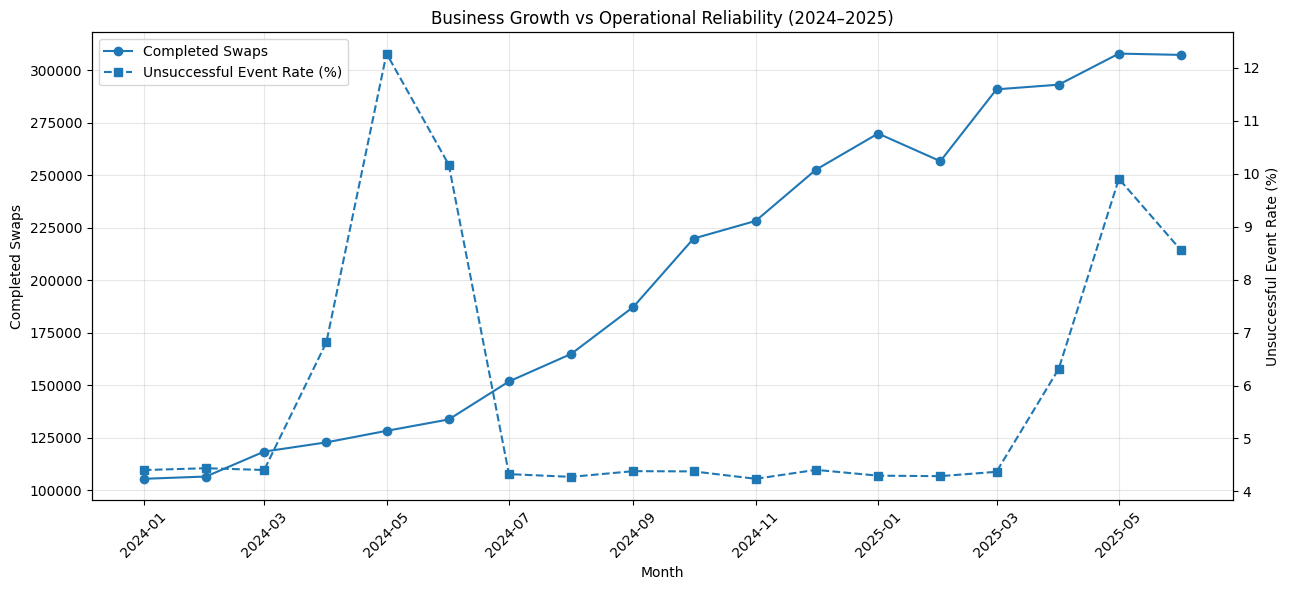

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

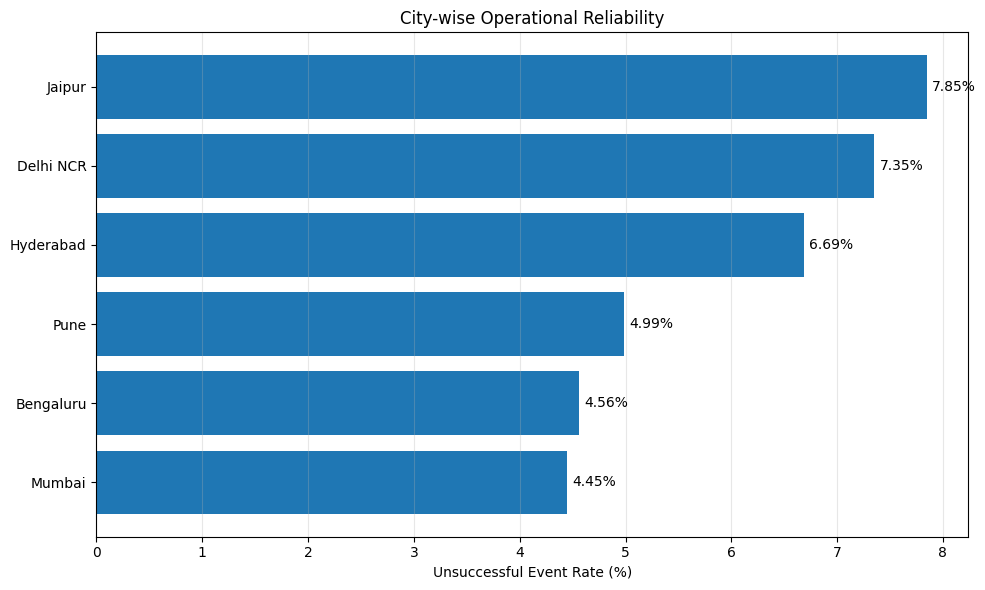

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

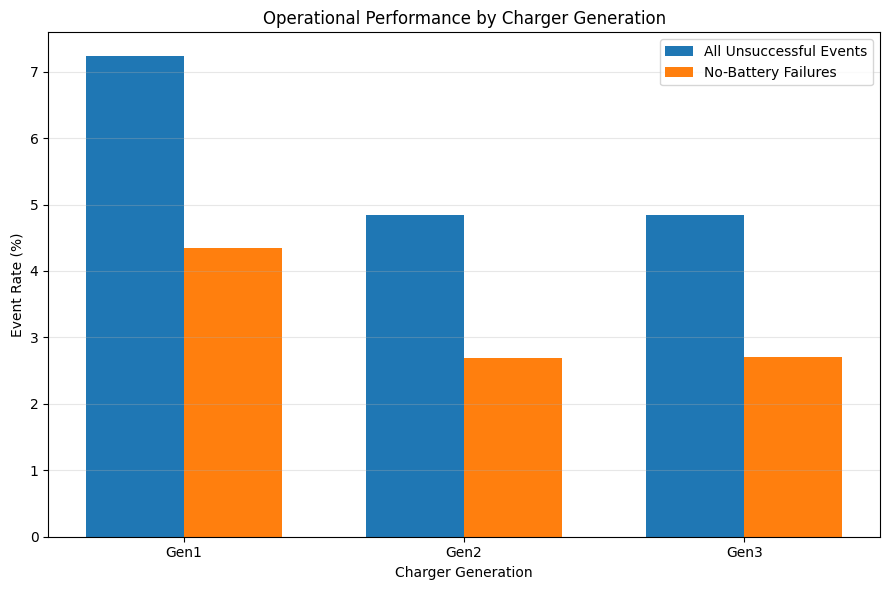

ALL 3 CHARTS CREATED AND SAVED SUCCESSFULLY!
Location: /content/volt_relay_charts/


In [55]:

import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("/content/volt_relay_charts", exist_ok=True)

# ---------------------------------------
# CHART 1: Monthly business performance
# ---------------------------------------

monthly = con.execute("""
SELECT
    month,
    completed_swaps,
    unsuccessful_events,
    total_events,
    recorded_revenue_inr
FROM monthly_business_baseline
ORDER BY month
""").df()

monthly["month"] = pd.to_datetime(monthly["month"])

fig, ax1 = plt.subplots(figsize=(13, 6))

ax1.plot(
    monthly["month"],
    monthly["completed_swaps"],
    marker="o",
    label="Completed Swaps"
)
ax1.set_xlabel("Month")
ax1.set_ylabel("Completed Swaps")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(
    monthly["month"],
    monthly["unsuccessful_events"] / monthly["total_events"] * 100,
    marker="s",
    linestyle="--",
    label="Unsuccessful Event Rate (%)"
)
ax2.set_ylabel("Unsuccessful Event Rate (%)")

lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc="upper left")

plt.title("Business Growth vs Operational Reliability (2024–2025)")
plt.tight_layout()
plt.savefig("/content/volt_relay_charts/chart1_monthly_performance.png", dpi=200)
plt.show()


# ---------------------------------------
# CHART 2: City-wise unsuccessful rate
# ---------------------------------------

city = con.execute("""
SELECT
    s.city,
    COUNT(*) AS total_events,
    COUNT(*) FILTER (
        WHERE e.event_type != 'swap_completed'
    ) AS unsuccessful_events
FROM swap_events_clean e
JOIN stations_clean s
    ON e.station_id = s.station_id
GROUP BY s.city
""").df()

city["unsuccessful_pct"] = (
    city["unsuccessful_events"] / city["total_events"] * 100
)

city = city.sort_values("unsuccessful_pct")

plt.figure(figsize=(10, 6))
bars = plt.barh(city["city"], city["unsuccessful_pct"])

plt.xlabel("Unsuccessful Event Rate (%)")
plt.title("City-wise Operational Reliability")
plt.grid(axis="x", alpha=0.3)

for bar, value in zip(bars, city["unsuccessful_pct"]):
    plt.text(
        value + 0.05,
        bar.get_y() + bar.get_height()/2,
        f"{value:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.savefig("/content/volt_relay_charts/chart2_city_performance.png", dpi=200)
plt.show()


# ---------------------------------------
# CHART 3: Charger generation comparison
# ---------------------------------------

generation = con.execute("""
SELECT
    s.charger_generation,
    COUNT(*) AS total_events,
    COUNT(*) FILTER (
        WHERE e.event_type != 'swap_completed'
    ) AS unsuccessful_events,
    COUNT(*) FILTER (
        WHERE e.event_type = 'failed_no_charged_battery'
    ) AS no_battery_failures
FROM swap_events_clean e
JOIN stations_clean s
    ON e.station_id = s.station_id
GROUP BY s.charger_generation
ORDER BY s.charger_generation
""").df()

generation["unsuccessful_pct"] = (
    generation["unsuccessful_events"] / generation["total_events"] * 100
)
generation["no_battery_pct"] = (
    generation["no_battery_failures"] / generation["total_events"] * 100
)

x = range(len(generation))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    [i - width/2 for i in x],
    generation["unsuccessful_pct"],
    width,
    label="All Unsuccessful Events"
)

plt.bar(
    [i + width/2 for i in x],
    generation["no_battery_pct"],
    width,
    label="No-Battery Failures"
)

plt.xticks(list(x), generation["charger_generation"])
plt.xlabel("Charger Generation")
plt.ylabel("Event Rate (%)")
plt.title("Operational Performance by Charger Generation")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/content/volt_relay_charts/chart3_generation_comparison.png", dpi=200)
plt.show()


print("ALL 3 CHARTS CREATED AND SAVED SUCCESSFULLY!")
print("Location: /content/volt_relay_charts/")



## Key Business Findings

### 1. Business Growth
- Completed swaps increased from 105,490 in January 2024 to 307,259 in June 2025, approximately 2.91 times growth.
- Recorded revenue increased from ₹6.32 million to ₹19.97 million.
- However, growth in transaction volume has not translated into improved operational reliability.

### 2. Operational Reliability
- Overall unsuccessful event rate was 5.96% across the observation period.
- The rate increased to 12.27% in May 2024 and 9.91% in May 2025.
- No-battery failures represent a major operational issue, particularly during high-failure months.
- Unsuccessful events include failed swaps, abandoned queues and rider cancellations; they should not all be interpreted as technical failures.

### 3. Geographic Performance
- Jaipur recorded the highest city-level unsuccessful event rate at 7.85%.
- Delhi NCR followed at 7.35%, while Hyderabad recorded 6.69%.
- Mumbai and Bengaluru had comparatively lower rates.

### 4. Infrastructure Performance
- Gen1 stations recorded a 7.23% unsuccessful event rate, compared with 4.84% for Gen2 and Gen3.
- Gen1 stations are also associated with the Launch expansion wave. Therefore, the difference cannot be attributed to charger generation alone.

## Business Recommendations

1. Prioritize operational audits and battery availability improvements in Jaipur, Delhi NCR and Hyderabad.
2. Investigate stations with consistently high unsuccessful event rates, especially Launch-wave Gen1 locations.
3. Review battery charging capacity and inventory planning ahead of recurring April–June high-failure periods.
4. Monitor no-battery failures, abandoned queues and system errors separately rather than relying on one combined failure metric.
5. Evaluate profitability using energy, rent, maintenance, battery and other operating costs before making claims about profit growth.

## Analytical Limitations

- The dataset contains synthetic operational records.
- Some battery commissioning dates are inconsistent with recorded usage dates.
- Charger generation and expansion wave are confounded.
- Recorded swap revenue is not equivalent to verified net profit.
- Observed seasonal patterns do not establish causation.


Data matching and coverage check

In [56]:

# Check whether swap events can be matched with hourly station status

matching_check = con.execute("""
WITH event_hours AS (
    SELECT
        station_id,
        DATE_TRUNC('hour', event_ts) AS hour_start,
        COUNT(*) AS total_events,
        COUNT(*) FILTER (
            WHERE event_type = 'failed_no_charged_battery'
        ) AS no_battery_failures
    FROM swap_events_clean
    GROUP BY 1, 2
)
SELECT
    COUNT(*) AS station_hour_combinations,
    SUM(total_events) AS total_events,
    SUM(no_battery_failures) AS no_battery_failures,
    COUNT(*) FILTER (
        WHERE h.station_id IS NOT NULL
    ) AS matched_station_hours,
    SUM(CASE WHEN h.station_id IS NOT NULL
        THEN e.total_events ELSE 0 END) AS matched_events,
    SUM(CASE WHEN h.station_id IS NULL
        THEN e.total_events ELSE 0 END) AS unmatched_events
FROM event_hours e
LEFT JOIN station_hourly_status_clean h
    ON e.station_id = h.station_id
    AND e.hour_start = h.hour_start
""").df()

display(matching_check)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,station_hour_combinations,total_events,no_battery_failures,matched_station_hours,matched_events,unmatched_events
0,1052566,3877013.0,134389.0,1052544,3876989.0,24.0


Battery availbilty vs no battery

In [58]:

con.execute("""
CREATE OR REPLACE VIEW station_hour_failure_analysis AS

WITH event_hour AS (
    SELECT
        station_id,
        DATE_TRUNC('hour', event_ts) AS hour_start,
        COUNT(*) AS total_events,

        COUNT(*) FILTER (
            WHERE event_type = 'swap_completed'
        ) AS completed_swaps,

        COUNT(*) FILTER (
            WHERE event_type = 'failed_no_charged_battery'
        ) AS no_battery_failures,

        COUNT(*) FILTER (
            WHERE event_type = 'failed_system_error'
        ) AS system_errors,

        COUNT(*) FILTER (
            WHERE event_type = 'abandoned_queue'
        ) AS abandoned_queues

    FROM swap_events_clean
    GROUP BY 1, 2
)

SELECT
    e.*,
    h.charged_2w_avg,
    h.charged_2w_min,
    h.packs_charging,
    h.packs_quarantined,
    h.chargers_online,
    h.outage_minutes,
    h.avg_charge_minutes,
    h.telemetry_status,

    CASE
        WHEN h.charged_2w_min IS NULL THEN 'Unknown'
        WHEN h.charged_2w_min = 0 THEN '0 available'
        WHEN h.charged_2w_min <= 2 THEN '1-2 available'
        WHEN h.charged_2w_min <= 5 THEN '3-5 available'
        ELSE '6+ available'
    END AS availability_band

FROM event_hour e
LEFT JOIN station_hourly_status_clean h
    ON e.station_id = h.station_id
    AND e.hour_start = h.hour_start
""")

print("Station-hour failure analysis view created!")


Station-hour failure analysis view created!


In [59]:

result = con.execute("""
SELECT
    availability_band,
    COUNT(*) AS station_hours,
    SUM(total_events) AS total_events,
    SUM(no_battery_failures) AS no_battery_failures,

    ROUND(
        100.0 * SUM(no_battery_failures)
        / NULLIF(SUM(total_events), 0),
        2
    ) AS no_battery_failure_pct,

    ROUND(AVG(charged_2w_avg), 2) AS avg_charged_batteries

FROM station_hour_failure_analysis
GROUP BY availability_band
ORDER BY
    CASE availability_band
        WHEN '0 available' THEN 1
        WHEN '1-2 available' THEN 2
        WHEN '3-5 available' THEN 3
        WHEN '6+ available' THEN 4
        ELSE 5
    END
""").df()

display(result)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,availability_band,station_hours,total_events,no_battery_failures,no_battery_failure_pct,avg_charged_batteries
0,0 available,15777,58631.0,4229.0,7.21,1.68
1,1-2 available,68625,266476.0,11356.0,4.26,3.73
2,3-5 available,304177,1151831.0,40576.0,3.52,5.78
3,6+ available,657237,2374350.0,77282.0,3.25,10.38
4,Unknown,6750,25725.0,946.0,3.68,NaN


Is high demand increase the failure

In [60]:

result = con.execute("""
WITH demand AS (
    SELECT
        *,
        NTILE(4) OVER (ORDER BY total_events) AS demand_quartile
    FROM station_hour_failure_analysis
    WHERE total_events > 0
)

SELECT
    demand_quartile,
    CASE demand_quartile
        WHEN 1 THEN 'Low demand'
        WHEN 2 THEN 'Moderate demand'
        WHEN 3 THEN 'High demand'
        WHEN 4 THEN 'Very high demand'
    END AS demand_level,

    COUNT(*) AS station_hours,
    SUM(total_events) AS total_events,
    SUM(no_battery_failures) AS no_battery_failures,

    ROUND(
        100.0 * SUM(no_battery_failures)
        / NULLIF(SUM(total_events), 0),
        2
    ) AS no_battery_failure_pct,

    ROUND(AVG(total_events), 2) AS avg_hourly_events,
    ROUND(AVG(charged_2w_min), 2) AS avg_min_available_batteries

FROM demand
GROUP BY demand_quartile
ORDER BY demand_quartile
""").df()

display(result)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,demand_quartile,demand_level,station_hours,total_events,no_battery_failures,no_battery_failure_pct,avg_hourly_events,avg_min_available_batteries
0,1,Low demand,263142,263142.0,8070.0,3.07,1.00,7.37
1,2,Moderate demand,263142,521174.0,17294.0,3.32,1.98,6.86
2,3,High demand,263141,981885.0,32380.0,3.30,3.73,6.90
3,4,Very high demand,263141,2110812.0,76645.0,3.63,8.02,6.78


Demand vs data availbilty

In [61]:

result = con.execute("""
WITH demand AS (
    SELECT
        *,
        NTILE(4) OVER (ORDER BY total_events) AS demand_quartile
    FROM station_hour_failure_analysis
    WHERE total_events > 0
)

SELECT
    CASE demand_quartile
        WHEN 1 THEN 'Low demand'
        WHEN 2 THEN 'Moderate demand'
        WHEN 3 THEN 'High demand'
        WHEN 4 THEN 'Very high demand'
    END AS demand_level,

    availability_band,

    COUNT(*) AS station_hours,
    SUM(total_events) AS total_events,
    SUM(no_battery_failures) AS no_battery_failures,

    ROUND(
        100.0 * SUM(no_battery_failures)
        / NULLIF(SUM(total_events), 0),
        2
    ) AS failure_rate_pct

FROM demand
GROUP BY demand_quartile, availability_band
ORDER BY demand_quartile,
    CASE availability_band
        WHEN '0 available' THEN 1
        WHEN '1-2 available' THEN 2
        WHEN '3-5 available' THEN 3
        WHEN '6+ available' THEN 4
        ELSE 5
    END
""").df()

display(result)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,demand_level,availability_band,station_hours,total_events,no_battery_failures,failure_rate_pct
0,Low demand,0 available,2830,2830.0,181.0,6.40
1,Low demand,1-2 available,14449,14449.0,507.0,3.51
2,Low demand,3-5 available,70489,70489.0,2179.0,3.09
3,Low demand,6+ available,173972,173972.0,5154.0,2.96
4,Low demand,Unknown,1402,1402.0,49.0,3.50
5,Moderate demand,0 available,4931,9822.0,698.0,7.11
6,Moderate demand,1-2 available,18165,37360.0,1528.0,4.09
7,Moderate demand,3-5 available,77814,157931.0,5383.0,3.41
8,Moderate demand,6+ available,160345,312645.0,9993.0,3.20
9,Moderate demand,Unknown,1887,3416.0,118.0,3.45



### Battery Availability and Demand Interaction

A consistent relationship was observed between minimum charged-battery availability and no-battery failures across all four demand quartiles.

During very high-demand station-hours, the no-battery failure rate was 7.30% when minimum charged-battery availability reached zero, compared with 3.40% when six or more batteries were available.

This pattern was also observed under low, moderate and high demand conditions. The findings suggest that maintaining adequate charged-battery availability may be an important operational priority, although the observational analysis does not establish causation.


Which time has more fialures

In [62]:

result = con.execute("""
SELECT
    EXTRACT(HOUR FROM hour_start) AS hour_of_day,

    COUNT(*) AS station_hours,
    SUM(total_events) AS total_events,
    SUM(no_battery_failures) AS no_battery_failures,

    ROUND(
        100.0 * SUM(no_battery_failures)
        / NULLIF(SUM(total_events), 0),
        2
    ) AS no_battery_failure_pct,

    ROUND(AVG(charged_2w_min), 2) AS avg_min_available

FROM station_hour_failure_analysis
GROUP BY 1
ORDER BY 1
""").df()

display(result)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,hour_of_day,station_hours,total_events,no_battery_failures,no_battery_failure_pct,avg_min_available
0,0,18824,23043.0,740.0,3.21,8.32
1,1,18917,23482.0,723.0,3.08,8.28
2,2,19403,25536.0,831.0,3.25,8.29
3,3,19602,28822.0,814.0,2.82,8.25
4,4,21422,31193.0,909.0,2.91,8.22
5,5,21081,28510.0,853.0,2.99,8.25
6,6,36237,62020.0,1932.0,3.12,8.16
7,7,36396,66889.0,2013.0,3.01,8.04
8,8,56182,171129.0,5579.0,3.26,7.76
9,9,59303,232933.0,7504.0,3.22,7.49


weekdays vs weekend

In [63]:

result = con.execute("""
WITH classified AS (
    SELECT
        *,
        EXTRACT(DOW FROM hour_start) AS day_number,
        EXTRACT(HOUR FROM hour_start) AS hour_of_day
    FROM station_hour_failure_analysis
)
SELECT
    CASE
        WHEN day_number IN (0, 6) THEN 'Weekend'
        ELSE 'Weekday'
    END AS day_type,

    COUNT(*) AS station_hours,
    SUM(total_events) AS total_events,
    SUM(no_battery_failures) AS no_battery_failures,

    ROUND(
        100.0 * SUM(no_battery_failures)
        / NULLIF(SUM(total_events), 0),
        2
    ) AS failure_rate_pct,

    ROUND(AVG(charged_2w_min), 2) AS avg_min_available

FROM classified
GROUP BY day_type
ORDER BY day_type
""").df()

display(result)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,day_type,station_hours,total_events,no_battery_failures,failure_rate_pct,avg_min_available
0,Weekday,749262,2725158.0,94326.0,3.46,6.98
1,Weekend,303304,1151855.0,40063.0,3.48,6.98


query hourly weekday vs weekend pattern

In [64]:

result_hourly = con.execute("""
WITH classified AS (
    SELECT
        *,
        EXTRACT(DOW FROM hour_start) AS day_number,
        EXTRACT(HOUR FROM hour_start) AS hour_of_day
    FROM station_hour_failure_analysis
)
SELECT
    hour_of_day,

    CASE
        WHEN day_number IN (0, 6) THEN 'Weekend'
        ELSE 'Weekday'
    END AS day_type,

    SUM(total_events) AS total_events,
    SUM(no_battery_failures) AS no_battery_failures,

    ROUND(
        100.0 * SUM(no_battery_failures)
        / NULLIF(SUM(total_events), 0),
        2
    ) AS failure_rate_pct

FROM classified
GROUP BY hour_of_day, day_type
ORDER BY hour_of_day, day_type
""").df()

display(result_hourly)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,hour_of_day,day_type,total_events,no_battery_failures,failure_rate_pct
0,0,Weekday,16248.0,524.0,3.23
1,0,Weekend,6795.0,216.0,3.18
2,1,Weekday,16581.0,501.0,3.02
3,1,Weekend,6901.0,222.0,3.22
4,2,Weekday,17891.0,565.0,3.16
5,2,Weekend,7645.0,266.0,3.48
6,3,Weekday,20436.0,586.0,2.87
7,3,Weekend,8386.0,228.0,2.72
8,4,Weekday,21945.0,659.0,3.00
9,4,Weekend,9248.0,250.0,2.70


In [65]:

station_priority = con.execute("""
SELECT
    s.station_id,
    s.city,
    s.zone,
    s.expansion_wave,
    s.charger_generation,

    COUNT(*) AS station_hours,
    SUM(a.total_events) AS total_events,
    SUM(a.no_battery_failures) AS no_battery_failures,

    ROUND(
        100.0 * SUM(a.no_battery_failures)
        / NULLIF(SUM(a.total_events), 0),
        2
    ) AS no_battery_failure_pct,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE a.charged_2w_min = 0
        ) / NULLIF(COUNT(*) FILTER (
            WHERE a.charged_2w_min IS NOT NULL
        ), 0),
        2
    ) AS zero_availability_hours_pct,

    ROUND(AVG(a.total_events), 2) AS avg_hourly_events

FROM station_hour_failure_analysis a
JOIN stations_clean s
    ON a.station_id = s.station_id

GROUP BY
    s.station_id,
    s.city,
    s.zone,
    s.expansion_wave,
    s.charger_generation

HAVING SUM(a.total_events) >= 1000

ORDER BY
    SUM(a.no_battery_failures) DESC
LIMIT 25
""").df()

display(station_priority)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,station_id,city,zone,expansion_wave,charger_generation,station_hours,total_events,no_battery_failures,no_battery_failure_pct,zero_availability_hours_pct,avg_hourly_events
0,STN-JAI-138,Jaipur,JAI-Malviya Nagar,Launch,Gen1,10029,48945.0,2635.0,5.38,4.67,4.88
1,STN-DEL-043,Delhi NCR,DEL-East,Launch,Gen1,10193,49597.0,2611.0,5.26,4.05,4.87
2,STN-HYD-072,Hyderabad,HYD-Hitech City,Launch,Gen1,10111,51765.0,2530.0,4.89,1.89,5.12
3,STN-DEL-050,Delhi NCR,DEL-East,Launch,Gen1,9926,47060.0,2513.0,5.34,4.12,4.74
4,STN-JAI-141,Jaipur,JAI-Malviya Nagar,Launch,Gen1,9926,45594.0,2474.0,5.43,3.70,4.59
5,STN-JAI-137,Jaipur,JAI-Malviya Nagar,Launch,Gen1,10014,44371.0,2380.0,5.36,8.63,4.43
6,STN-JAI-140,Jaipur,JAI-Malviya Nagar,Launch,Gen1,9955,44115.0,2347.0,5.32,3.60,4.43
7,STN-HYD-070,Hyderabad,HYD-South,Launch,Gen1,10211,49688.0,2311.0,4.65,1.10,4.87
8,STN-JAI-134,Jaipur,JAI-Malviya Nagar,Launch,Gen1,9907,42925.0,2221.0,5.17,3.86,4.33
9,STN-DEL-047,Delhi NCR,DEL-South,Launch,Gen1,9820,41594.0,2141.0,5.15,4.06,4.24


City zone concentraion analysis

In [66]:

zone_analysis = con.execute("""
SELECT
    s.city,
    s.zone,
    COUNT(DISTINCT s.station_id) AS station_count,

    SUM(a.total_events) AS total_events,
    SUM(a.no_battery_failures) AS no_battery_failures,

    ROUND(
        100.0 * SUM(a.no_battery_failures)
        / NULLIF(SUM(a.total_events), 0),
        2
    ) AS no_battery_failure_pct,

    ROUND(AVG(a.charged_2w_min), 2) AS avg_min_available,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE a.charged_2w_min = 0
        ) / NULLIF(COUNT(*) FILTER (
            WHERE a.charged_2w_min IS NOT NULL
        ), 0),
        2
    ) AS zero_availability_hours_pct

FROM station_hour_failure_analysis a
JOIN stations_clean s
    ON a.station_id = s.station_id

GROUP BY s.city, s.zone
HAVING SUM(a.total_events) >= 5000
ORDER BY no_battery_failures DESC
""").df()

display(zone_analysis)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,city,zone,station_count,total_events,no_battery_failures,no_battery_failure_pct,avg_min_available,zero_availability_hours_pct
0,Jaipur,JAI-Malviya Nagar,10,310571.0,15393.0,4.96,6.16,4.42
1,Hyderabad,HYD-Central,10,236099.0,9250.0,3.92,7.45,1.56
2,Delhi NCR,DEL-East,7,204522.0,9219.0,4.51,5.87,2.76
3,Delhi NCR,DEL-Noida,6,184463.0,8162.0,4.42,7.31,1.98
4,Pune,PUN-South,12,252051.0,7231.0,2.87,7.93,0.24
5,Hyderabad,HYD-Secunderabad,6,174210.0,7167.0,4.11,6.07,2.00
6,Jaipur,JAI-Vaishali,7,150511.0,7120.0,4.73,7.15,3.32
7,Hyderabad,HYD-Hitech City,5,178198.0,6899.0,3.87,6.49,1.01
8,Delhi NCR,DEL-West,8,156655.0,6890.0,4.40,6.42,2.73
9,Bengaluru,BLR-Central,10,243058.0,6000.0,2.47,6.05,0.74


operational findings from Customer complaints

In [67]:

ticket_validation = con.execute("""
SELECT
    s.city,

    COUNT(*) AS total_tickets,

    COUNT(*) FILTER (
        WHERE t.category = 'no_battery_available'
    ) AS no_battery_tickets,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE t.category = 'no_battery_available'
        ) / NULLIF(COUNT(*), 0),
        2
    ) AS no_battery_ticket_pct,

    COUNT(*) FILTER (
        WHERE t.category = 'long_queue'
    ) AS long_queue_tickets,

    COUNT(*) FILTER (
        WHERE t.resolution_status = 'resolved'
    ) AS resolved_tickets,

    ROUND(
        AVG(t.resolution_hours) FILTER (
            WHERE t.resolution_status = 'resolved'
        ),
        2
    ) AS avg_resolution_hours,

    ROUND(
        AVG(t.csat_score),
        2
    ) AS avg_csat

FROM support_tickets_clean t
JOIN stations_clean s
    ON t.station_id = s.station_id

GROUP BY s.city
ORDER BY no_battery_tickets DESC
""").df()

display(ticket_validation)


,city,total_tickets,no_battery_tickets,no_battery_ticket_pct,long_queue_tickets,resolved_tickets,avg_resolution_hours,avg_csat
0,Delhi NCR,9907,2823,28.50,1309,8554,16.06,3.56
1,Hyderabad,8594,2240,26.06,1138,7429,15.84,3.55
2,Jaipur,6536,1958,29.96,868,5612,16.09,3.56
3,Bengaluru,7187,1716,23.88,921,6213,15.81,3.57
4,Pune,5032,1268,25.20,647,4300,16.07,3.57
5,Mumbai,4517,1075,23.80,570,3889,15.91,3.53


Rider cohort retention

In [68]:

retention = con.execute("""
WITH cohorts AS (
    SELECT
        rider_id,
        DATE_TRUNC('month', signup_date)::DATE AS cohort_month
    FROM riders_clean
),
activity AS (
    SELECT DISTINCT
        rider_id,
        DATE_TRUNC('month', event_ts)::DATE AS activity_month
    FROM swap_events_clean
    WHERE event_type = 'swap_completed'
),
cohort_activity AS (
    SELECT
        c.cohort_month,
        DATE_DIFF(
            'month',
            c.cohort_month,
            a.activity_month
        ) AS month_number,
        c.rider_id
    FROM cohorts c
    JOIN activity a
        ON c.rider_id = a.rider_id
    WHERE a.activity_month >= c.cohort_month
),
cohort_sizes AS (
    SELECT
        cohort_month,
        COUNT(DISTINCT rider_id) AS cohort_size
    FROM cohorts
    GROUP BY cohort_month
),
retained AS (
    SELECT
        cohort_month,
        COUNT(DISTINCT rider_id) FILTER (
            WHERE month_number = 0
        ) AS month_0,
        COUNT(DISTINCT rider_id) FILTER (
            WHERE month_number = 1
        ) AS month_1,
        COUNT(DISTINCT rider_id) FILTER (
            WHERE month_number = 2
        ) AS month_2,
        COUNT(DISTINCT rider_id) FILTER (
            WHERE month_number = 3
        ) AS month_3
    FROM cohort_activity
    WHERE month_number BETWEEN 0 AND 3
    GROUP BY cohort_month
)
SELECT
    s.cohort_month,
    s.cohort_size,
    COALESCE(r.month_0, 0) AS month_0_active,
    COALESCE(r.month_1, 0) AS month_1_active,
    COALESCE(r.month_2, 0) AS month_2_active,
    COALESCE(r.month_3, 0) AS month_3_active,

    ROUND(100.0 * COALESCE(r.month_0, 0) / s.cohort_size, 2)
        AS month_0_retention_pct,
    ROUND(100.0 * COALESCE(r.month_1, 0) / s.cohort_size, 2)
        AS month_1_retention_pct,
    ROUND(100.0 * COALESCE(r.month_2, 0) / s.cohort_size, 2)
        AS month_2_retention_pct,
    ROUND(100.0 * COALESCE(r.month_3, 0) / s.cohort_size, 2)
        AS month_3_retention_pct

FROM cohort_sizes s
LEFT JOIN retained r
    ON s.cohort_month = r.cohort_month
ORDER BY s.cohort_month
""").df()

display(retention)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,cohort_month,cohort_size,month_0_active,month_1_active,month_2_active,month_3_active,month_0_retention_pct,month_1_retention_pct,month_2_retention_pct,month_3_retention_pct
0,2023-03-01,323,0,0,0,0,0.00,0.00,0.00,0.00
1,2023-04-01,406,0,0,0,0,0.00,0.00,0.00,0.00
2,2023-05-01,367,0,0,0,0,0.00,0.00,0.00,0.00
3,2023-06-01,427,0,0,0,0,0.00,0.00,0.00,0.00
4,2023-07-01,388,0,0,0,0,0.00,0.00,0.00,0.00
5,2023-08-01,435,0,0,0,0,0.00,0.00,0.00,0.00
6,2023-09-01,433,0,0,0,0,0.00,0.00,0.00,0.00
7,2023-10-01,392,0,0,0,392,0.00,0.00,0.00,100.00
8,2023-11-01,405,0,0,405,381,0.00,0.00,100.00,94.07
9,2023-12-01,24,0,24,23,23,0.00,100.00,95.83,95.83


Which rider segment is losing the retention

In [69]:

segment_retention = con.execute("""
WITH cohort_riders AS (
    SELECT
        rider_id,
        customer_channel,
        plan_type,
        vehicle_class,
        DATE_TRUNC('month', signup_date)::DATE AS cohort_month
    FROM riders_clean
    WHERE signup_date >= DATE '2024-01-01'
      AND signup_date < DATE '2025-01-01'
),
activity AS (
    SELECT DISTINCT
        rider_id,
        DATE_TRUNC('month', event_ts)::DATE AS activity_month
    FROM swap_events_clean
    WHERE event_type = 'swap_completed'
),
rider_retention AS (
    SELECT
        c.rider_id,
        c.customer_channel,
        c.plan_type,
        c.vehicle_class,
        DATE_DIFF(
            'month',
            c.cohort_month,
            a.activity_month
        ) AS month_number
    FROM cohort_riders c
    LEFT JOIN activity a
        ON c.rider_id = a.rider_id
       AND a.activity_month >= c.cohort_month
       AND a.activity_month <= DATE '2025-06-01'
)
SELECT
    customer_channel,
    plan_type,
    vehicle_class,
    COUNT(DISTINCT rider_id) AS cohort_size,

    COUNT(DISTINCT rider_id) FILTER (
        WHERE month_number = 1
    ) AS month_1_active,

    COUNT(DISTINCT rider_id) FILTER (
        WHERE month_number = 3
    ) AS month_3_active,

    ROUND(
        100.0 * COUNT(DISTINCT rider_id) FILTER (
            WHERE month_number = 1
        ) / COUNT(DISTINCT rider_id),
        2
    ) AS month_1_retention_pct,

    ROUND(
        100.0 * COUNT(DISTINCT rider_id) FILTER (
            WHERE month_number = 3
        ) / COUNT(DISTINCT rider_id),
        2
    ) AS month_3_retention_pct

FROM rider_retention
GROUP BY customer_channel, plan_type, vehicle_class
HAVING COUNT(DISTINCT rider_id) >= 100
ORDER BY month_3_retention_pct ASC
""").df()

display(segment_retention)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customer_channel,plan_type,vehicle_class,cohort_size,month_1_active,month_3_active,month_1_retention_pct,month_3_retention_pct
0,direct,prepaid_pack,3W,101,90,74,89.11,73.27
1,partner,partner_billed,3W,1056,962,783,91.10,74.15
2,direct,pay_as_you_go,3W,227,204,176,89.87,77.53
3,partner,partner_billed,2W,4857,4484,3807,92.32,78.38
4,direct,pay_as_you_go,2W,2408,2248,1930,93.36,80.15
5,direct,prepaid_pack,2W,1037,958,834,92.38,80.42


Unit economics

In [70]:

unit_economics = con.execute("""
WITH monthly_revenue AS (
    SELECT
        station_id,
        DATE_TRUNC('month', event_ts)::DATE AS month,
        COUNT(*) FILTER (
            WHERE event_type = 'swap_completed'
        ) AS completed_swaps,
        SUM(
            CASE WHEN event_type = 'swap_completed'
            THEN amount_charged_inr ELSE 0 END
        ) AS recorded_revenue,
        SUM(
            CASE WHEN event_type = 'swap_completed'
            THEN discount_inr ELSE 0 END
        ) AS discounts
    FROM swap_events_clean
    GROUP BY 1, 2
),
monthly_energy AS (
    SELECT
        station_id,
        DATE_TRUNC('month', hour_start)::DATE AS month,
        SUM(grid_kwh) AS grid_energy_kwh
    FROM station_hourly_status_clean
    GROUP BY 1, 2
),
station_months AS (
    SELECT
        r.station_id,
        r.month,
        r.completed_swaps,
        r.recorded_revenue,
        r.discounts,
        COALESCE(e.grid_energy_kwh, 0) AS grid_energy_kwh,
        COALESCE(e.grid_energy_kwh, 0)
            * s.grid_tariff_inr_kwh AS electricity_cost,
        s.monthly_rent_inr,
        s.monthly_maintenance_inr
    FROM monthly_revenue r
    JOIN stations_clean s
        ON r.station_id = s.station_id
    LEFT JOIN monthly_energy e
        ON r.station_id = e.station_id
       AND r.month = e.month
    WHERE s.commissioned_date <=
          (r.month + INTERVAL '1 month' - INTERVAL '1 day')
      AND (
          s.decommissioned_date IS NULL
          OR s.decommissioned_date >= r.month
      )
)
SELECT
    month,
    SUM(completed_swaps) AS completed_swaps,
    ROUND(SUM(recorded_revenue), 2) AS recorded_revenue_inr,
    ROUND(SUM(discounts), 2) AS discounts_inr,
    ROUND(SUM(grid_energy_kwh), 2) AS grid_energy_kwh,
    ROUND(SUM(electricity_cost), 2) AS electricity_cost_inr,
    ROUND(SUM(monthly_rent_inr + monthly_maintenance_inr), 2)
        AS fixed_station_cost_inr,

    ROUND(
        SUM(recorded_revenue)
        - SUM(electricity_cost)
        - SUM(monthly_rent_inr + monthly_maintenance_inr),
        2
    ) AS contribution_proxy_inr,

    ROUND(
        (
            SUM(recorded_revenue)
            - SUM(electricity_cost)
            - SUM(monthly_rent_inr + monthly_maintenance_inr)
        ) / NULLIF(SUM(completed_swaps), 0),
        2
    ) AS contribution_proxy_per_swap

FROM station_months
GROUP BY month
ORDER BY month
""").df()

display(unit_economics)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,completed_swaps,recorded_revenue_inr,discounts_inr,grid_energy_kwh,electricity_cost_inr,fixed_station_cost_inr,contribution_proxy_inr,contribution_proxy_per_swap
0,2024-01-01,105490.0,6318995.20,482814.80,539602.14,5014232.82,2143096.0,-838333.62,-7.95
1,2024-02-01,106582.0,6387614.80,489395.20,504286.23,4684346.25,2143096.0,-439827.45,-4.13
2,2024-03-01,118444.0,7093617.00,540193.00,542202.84,5039010.09,2143096.0,-88489.09,-0.75
3,2024-04-01,122836.0,7370255.80,556189.20,523181.84,4860735.17,2143096.0,366424.63,2.98
4,2024-05-01,128328.0,7689594.00,579311.00,541373.11,5030109.05,2143096.0,516388.95,4.02
5,2024-06-01,133743.0,8003275.60,599949.40,522404.10,4852715.28,2143096.0,1007464.32,7.53
6,2024-07-01,151824.0,9879524.60,738545.40,540885.06,5025386.92,2143096.0,2711041.68,17.86
7,2024-08-01,164931.0,10724296.65,805583.35,559647.74,5204242.11,2405333.0,3114721.54,18.88
8,2024-09-01,187302.0,12115209.50,914095.50,596710.87,5550556.00,2582737.0,3981916.50,21.26
9,2024-10-01,219838.0,14577271.65,1079868.35,680535.15,6326938.08,2880895.0,5369438.57,24.42


In [71]:

economics_validation = con.execute("""
SELECT
    DATE_TRUNC('month', event_ts)::DATE AS month,

    COUNT(DISTINCT station_id) AS stations_with_events,

    ROUND(
        SUM(CASE WHEN event_type = 'swap_completed'
            THEN list_price_inr ELSE 0 END), 2
    ) AS list_price_total,

    ROUND(
        SUM(CASE WHEN event_type = 'swap_completed'
            THEN discount_inr ELSE 0 END), 2
    ) AS discount_total,

    ROUND(
        SUM(CASE WHEN event_type = 'swap_completed'
            THEN amount_charged_inr ELSE 0 END), 2
    ) AS amount_charged_total,

    ROUND(
        SUM(CASE WHEN event_type = 'swap_completed'
            THEN list_price_inr - discount_inr ELSE 0 END), 2
    ) AS expected_net_amount,

    ROUND(
        SUM(CASE WHEN event_type = 'swap_completed'
            THEN amount_charged_inr
                 - (list_price_inr - discount_inr)
            ELSE 0 END), 2
    ) AS revenue_difference

FROM swap_events_clean
GROUP BY 1
ORDER BY 1
""").df()

display(economics_validation)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,stations_with_events,list_price_total,discount_total,amount_charged_total,expected_net_amount,revenue_difference
0,2024-01-01,92,6801640.0,482814.80,6318995.20,6318825.20,170.0
1,2024-02-01,92,6876760.0,489395.20,6387614.80,6387364.80,250.0
2,2024-03-01,92,7633800.0,540193.00,7093617.00,7093607.00,10.0
3,2024-04-01,92,7926520.0,556189.20,7370255.80,7370330.80,-75.0
4,2024-05-01,92,8268880.0,579311.00,7689594.00,7689569.00,25.0
5,2024-06-01,92,8603380.0,599949.40,8003275.60,8003430.60,-155.0
6,2024-07-01,92,10617990.0,738545.40,9879524.60,9879444.60,80.0
7,2024-08-01,102,11529750.0,805583.35,10724296.65,10724166.65,130.0
8,2024-09-01,110,13029405.0,914095.50,12115209.50,12115309.50,-100.0
9,2024-10-01,122,15274070.0,1079868.35,14577271.65,14194201.65,383070.0


In [72]:

revenue_reconciliation = con.execute("""
SELECT
    DATE_TRUNC('month', e.event_ts)::DATE AS month,
    e.tariff_code,
    r.customer_channel,
    r.plan_type,

    COUNT(*) AS completed_swaps,

    ROUND(SUM(e.list_price_inr), 2) AS list_price,
    ROUND(SUM(e.discount_inr), 2) AS discounts,
    ROUND(SUM(e.amount_charged_inr), 2) AS amount_charged,

    ROUND(
        SUM(e.amount_charged_inr
            - (e.list_price_inr - e.discount_inr)), 2
    ) AS reconciliation_difference

FROM swap_events_clean e
JOIN riders_clean r
    ON e.rider_id = r.rider_id

WHERE e.event_type = 'swap_completed'
  AND e.event_ts >= TIMESTAMP '2024-09-01'
  AND e.event_ts < TIMESTAMP '2025-07-01'

GROUP BY 1, 2, 3, 4
ORDER BY 1, 2, 3, 4
""").df()

display(revenue_reconciliation)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,tariff_code,customer_channel,plan_type,completed_swaps,list_price,discounts,amount_charged,reconciliation_difference
0,2024-09-01,PARTNER,partner,partner_billed,123240,8717595.0,914095.5,7803384.5,-115.0
1,2024-09-01,STD,direct,pay_as_you_go,44284,2982680.0,0.0,2982720.0,40.0
2,2024-09-01,STD,direct,prepaid_pack,19778,1329130.0,0.0,1329105.0,-25.0
3,2024-10-01,OFFPEAK,direct,pay_as_you_go,2209,149210.0,0.0,131558.0,-17652.0
4,2024-10-01,OFFPEAK,direct,prepaid_pack,1020,68145.0,0.0,59995.0,-8150.0
...,...,...,...,...,...,...,...,...,...
61,2025-06-01,PARTNER,partner,partner_billed,202641,14350125.0,1997449.0,12613796.0,261120.0
62,2025-06-01,PEAK,direct,pay_as_you_go,15329,1041970.0,0.0,1271910.0,229940.0
63,2025-06-01,PEAK,direct,prepaid_pack,6937,463865.0,0.0,567920.0,104055.0
64,2025-06-01,STD,direct,pay_as_you_go,54324,3662460.0,0.0,3662520.0,60.0


Dashboard Visuluzation

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

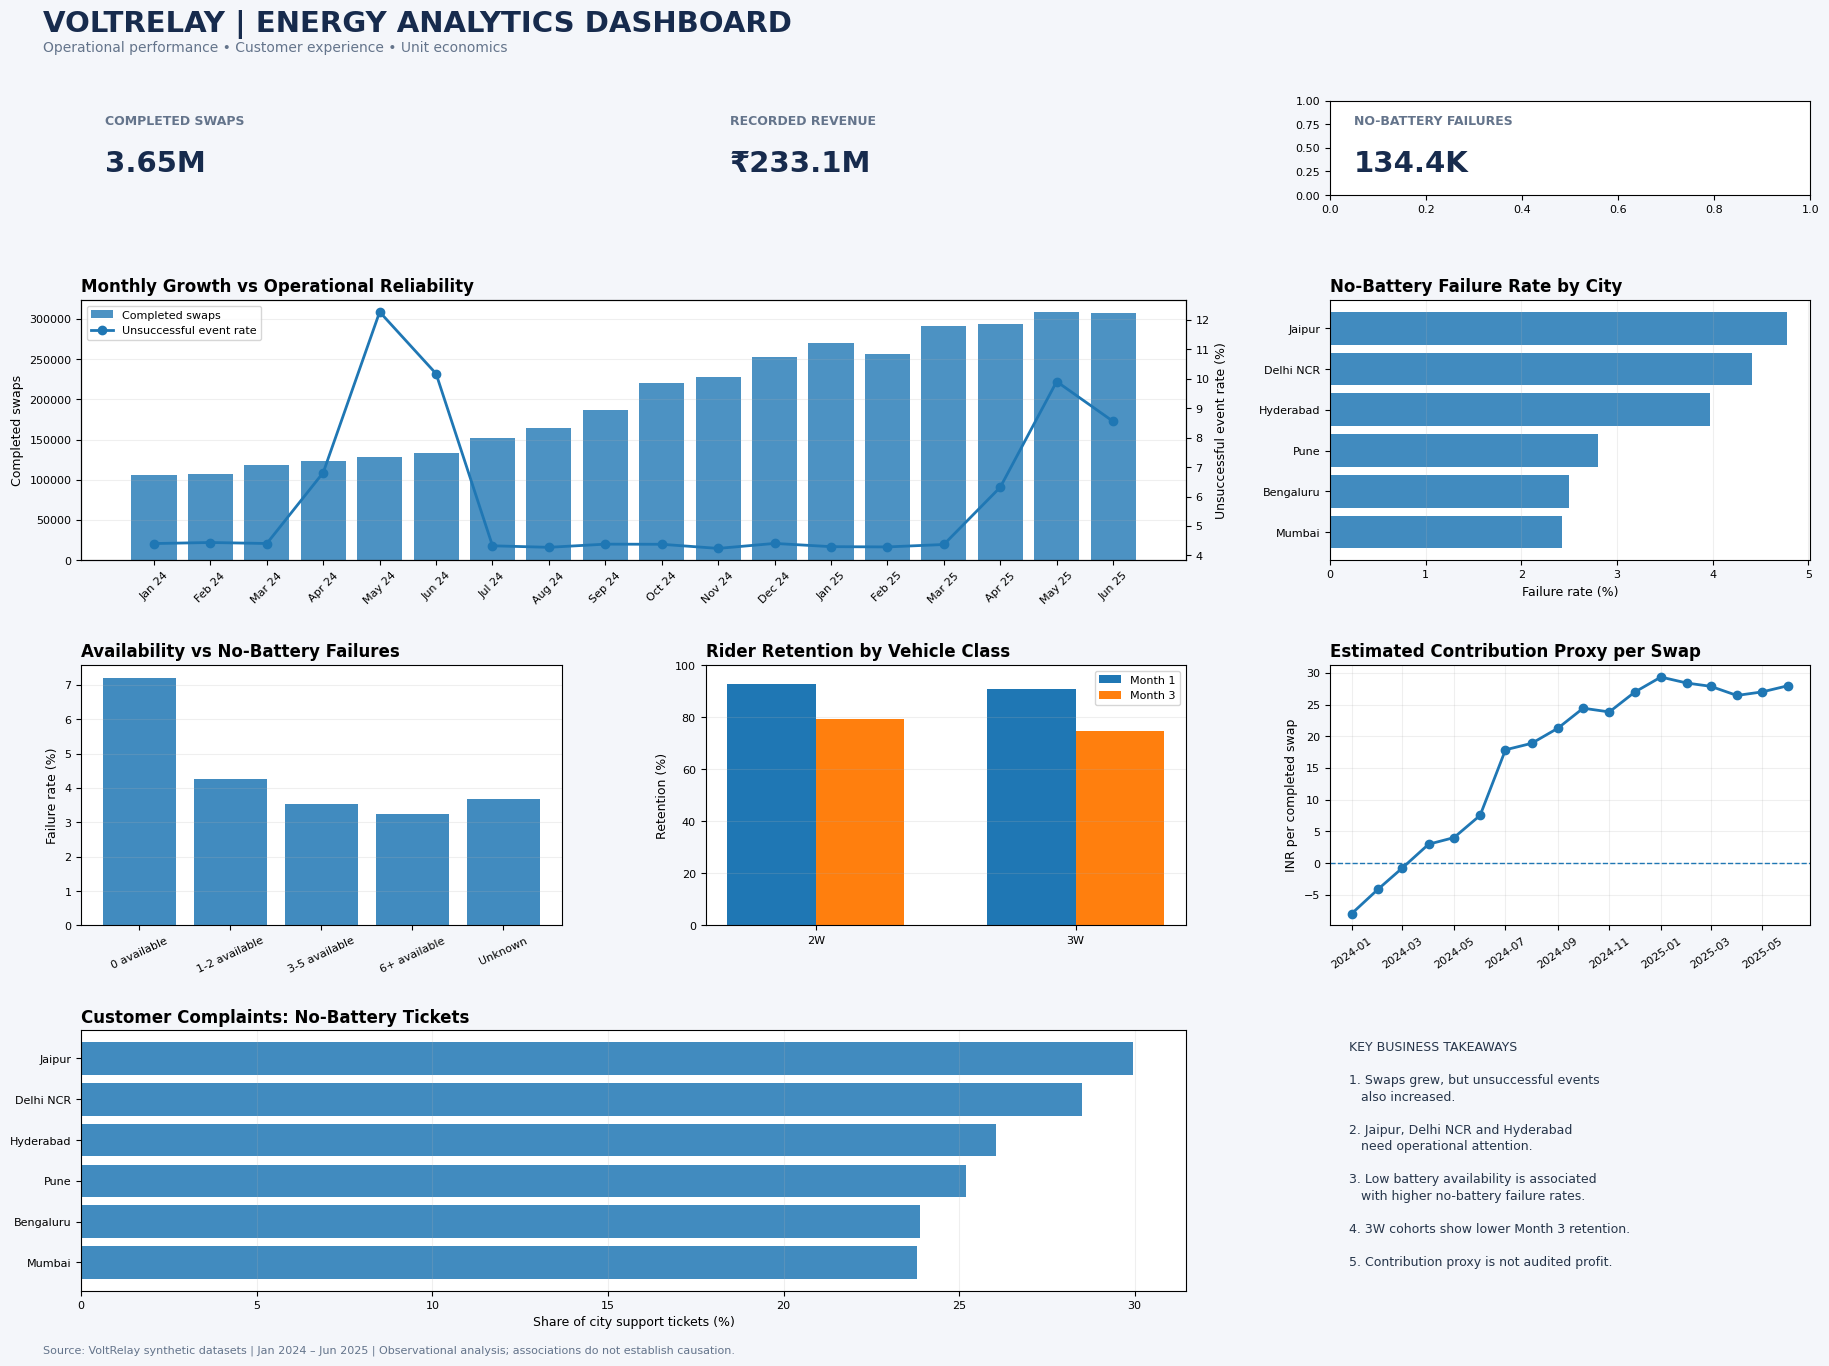

Dashboard saved successfully:
/content/volt_relay_dashboard/VoltRelay_Analytics_Dashboard.png
/content/volt_relay_dashboard/VoltRelay_Analytics_Dashboard.pdf


In [73]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# Separate folder: old 3 charts remain untouched
output_dir = "/content/volt_relay_dashboard"
os.makedirs(output_dir, exist_ok=True)

# -----------------------------------------
# 1. Fetch analysis results
# -----------------------------------------

monthly = con.execute("""
    SELECT *
    FROM monthly_business_baseline
    ORDER BY month
""").df()

city = con.execute("""
    SELECT
        s.city,
        SUM(a.total_events) AS total_events,
        SUM(a.no_battery_failures) AS no_battery_failures,
        ROUND(
            100.0 * SUM(a.no_battery_failures)
            / NULLIF(SUM(a.total_events), 0), 2
        ) AS no_battery_failure_pct
    FROM station_hour_failure_analysis a
    JOIN stations_clean s
        ON a.station_id = s.station_id
    GROUP BY s.city
    ORDER BY no_battery_failure_pct DESC
""").df()

availability = con.execute("""
    SELECT
        availability_band,
        SUM(total_events) AS total_events,
        SUM(no_battery_failures) AS no_battery_failures,
        ROUND(
            100.0 * SUM(no_battery_failures)
            / NULLIF(SUM(total_events), 0), 2
        ) AS failure_rate
    FROM station_hour_failure_analysis
    GROUP BY availability_band
""").df()

# Keep availability categories in meaningful order
availability_order = [
    "0 available", "1-2 available",
    "3-5 available", "6+ available", "Unknown"
]
availability["availability_band"] = pd.Categorical(
    availability["availability_band"],
    categories=availability_order,
    ordered=True
)
availability = availability.sort_values("availability_band")

# Existing analysis DataFrames
ret = segment_retention.copy()
econ = unit_economics.copy()
tickets = ticket_validation.copy()

# -----------------------------------------
# 2. Calculate KPI values
# -----------------------------------------

total_events = monthly["total_events"].sum()
completed = monthly["completed_swaps"].sum()
unsuccessful = monthly["unsuccessful_events"].sum()
no_battery = monthly["no_battery_failures"].sum()
revenue = monthly["recorded_revenue_inr"].sum()

unsuccessful_rate = 100 * unsuccessful / total_events

# -----------------------------------------
# 3. Dashboard layout
# -----------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titlesize": 12,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8
})

fig = plt.figure(figsize=(19, 14), facecolor="#F4F6FA")

gs = GridSpec(
    4, 3,
    figure=fig,
    height_ratios=[0.8, 2.2, 2.2, 2.2],
    hspace=0.48,
    wspace=0.30
)

# -----------------------------------------
# 4. Dashboard title
# -----------------------------------------

fig.text(
    0.04, 0.975,
    "VOLTRELAY | ENERGY ANALYTICS DASHBOARD",
    fontsize=21, fontweight="bold",
    color="#172B4D", va="top"
)

fig.text(
    0.04, 0.945,
    "Operational performance • Customer experience • Unit economics",
    fontsize=10, color="#64748B"
)

# -----------------------------------------
# 5. KPI cards
# -----------------------------------------

kpis = [
    ("COMPLETED SWAPS", f"{completed/1e6:.2f}M"),
    ("RECORDED REVENUE", f"₹{revenue/1e6:.1f}M"),
    ("UNSUCCESSFUL EVENTS", f"{unsuccessful_rate:.2f}%"),
    ("NO-BATTERY FAILURES", f"{no_battery/1000:.1f}K")
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i if i < 3 else 2])
    if i == 3:
        ax = fig.add_subplot(gs[0, 2])
    ax.axis("off")
    ax.text(
        0.05, 0.75, label,
        fontsize=9, color="#64748B",
        fontweight="bold", transform=ax.transAxes
    )
    ax.text(
        0.05, 0.25, value,
        fontsize=21, color="#172B4D",
        fontweight="bold", transform=ax.transAxes
    )
    ax.set_facecolor("white")
    ax.patch.set_visible(True)

# -----------------------------------------
# 6. Monthly swaps and unsuccessful rate
# -----------------------------------------

ax1 = fig.add_subplot(gs[1, :2])
ax1.set_facecolor("white")

months = pd.to_datetime(monthly["month"]).dt.strftime("%b %y")

ax1.bar(
    months,
    monthly["completed_swaps"],
    label="Completed swaps",
    alpha=0.8
)

ax2 = ax1.twinx()
ax2.plot(
    months,
    100 * monthly["unsuccessful_events"] / monthly["total_events"],
    marker="o",
    linewidth=2,
    label="Unsuccessful event rate"
)

ax1.set_title("Monthly Growth vs Operational Reliability",
              loc="left", fontweight="bold")
ax1.set_ylabel("Completed swaps")
ax2.set_ylabel("Unsuccessful event rate (%)")
ax1.tick_params(axis="x", rotation=45)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=8)

ax1.grid(axis="y", alpha=0.2)

# -----------------------------------------
# 7. City-wise reliability
# -----------------------------------------

ax = fig.add_subplot(gs[1, 2])
ax.set_facecolor("white")

city_plot = city.sort_values("no_battery_failure_pct")

ax.barh(
    city_plot["city"],
    city_plot["no_battery_failure_pct"],
    alpha=0.85
)

ax.set_title("No-Battery Failure Rate by City",
             loc="left", fontweight="bold")
ax.set_xlabel("Failure rate (%)")
ax.grid(axis="x", alpha=0.2)

# -----------------------------------------
# 8. Battery availability impact
# -----------------------------------------

ax = fig.add_subplot(gs[2, 0])
ax.set_facecolor("white")

ax.bar(
    availability["availability_band"].astype(str),
    availability["failure_rate"],
    alpha=0.85
)

ax.set_title("Availability vs No-Battery Failures",
             loc="left", fontweight="bold")
ax.set_ylabel("Failure rate (%)")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.2)

# -----------------------------------------
# 9. Rider retention: 2W vs 3W
# -----------------------------------------

ax = fig.add_subplot(gs[2, 1])
ax.set_facecolor("white")

ret["cohort_size"] = pd.to_numeric(ret["cohort_size"])

ret_summary = ret.groupby("vehicle_class").apply(
    lambda x: pd.Series({
        "month_1": 100 * x["month_1_active"].sum()
                       / x["cohort_size"].sum(),
        "month_3": 100 * x["month_3_active"].sum()
                       / x["cohort_size"].sum()
    }),
    include_groups=False
)

x = np.arange(len(ret_summary))
width = 0.34

ax.bar(
    x - width/2, ret_summary["month_1"],
    width, label="Month 1"
)
ax.bar(
    x + width/2, ret_summary["month_3"],
    width, label="Month 3"
)

ax.set_xticks(x)
ax.set_xticklabels(ret_summary.index)
ax.set_ylim(0, 100)
ax.set_title("Rider Retention by Vehicle Class",
             loc="left", fontweight="bold")
ax.set_ylabel("Retention (%)")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.2)

# -----------------------------------------
# 10. Contribution proxy per swap
# -----------------------------------------

ax = fig.add_subplot(gs[2, 2])
ax.set_facecolor("white")

econ["month"] = pd.to_datetime(econ["month"])

ax.plot(
    econ["month"],
    econ["contribution_proxy_per_swap"],
    marker="o",
    linewidth=2
)
ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title("Estimated Contribution Proxy per Swap",
             loc="left", fontweight="bold")
ax.set_ylabel("INR per completed swap")
ax.tick_params(axis="x", rotation=35)
ax.grid(alpha=0.2)

# -----------------------------------------
# 11. Customer complaints
# -----------------------------------------

ax = fig.add_subplot(gs[3, :2])
ax.set_facecolor("white")

ticket_plot = tickets.sort_values("no_battery_ticket_pct")

ax.barh(
    ticket_plot["city"],
    ticket_plot["no_battery_ticket_pct"],
    alpha=0.85
)

ax.set_title("Customer Complaints: No-Battery Tickets",
             loc="left", fontweight="bold")
ax.set_xlabel("Share of city support tickets (%)")
ax.grid(axis="x", alpha=0.2)

# -----------------------------------------
# 12. Key business insights
# -----------------------------------------

ax = fig.add_subplot(gs[3, 2])
ax.axis("off")
ax.set_facecolor("white")

insights = [
    "KEY BUSINESS TAKEAWAYS",
    "",
    "1. Swaps grew, but unsuccessful events",
    "   also increased.",
    "",
    "2. Jaipur, Delhi NCR and Hyderabad",
    "   need operational attention.",
    "",
    "3. Low battery availability is associated",
    "   with higher no-battery failure rates.",
    "",
    "4. 3W cohorts show lower Month 3 retention.",
    "",
    "5. Contribution proxy is not audited profit."
]

ax.text(
    0.04, 0.96,
    "\n".join(insights),
    transform=ax.transAxes,
    va="top",
    fontsize=9,
    color="#26354A",
    linespacing=1.35
)

# -----------------------------------------
# 13. Footer and save
# -----------------------------------------

fig.text(
    0.04, 0.015,
    "Source: VoltRelay synthetic datasets | Jan 2024 – Jun 2025"
    " | Observational analysis; associations do not establish causation.",
    fontsize=8, color="#64748B"
)

plt.subplots_adjust(
    top=0.91, bottom=0.06,
    left=0.06, right=0.97
)

dashboard_path = os.path.join(
    output_dir, "VoltRelay_Analytics_Dashboard.png"
)

pdf_path = os.path.join(
    output_dir, "VoltRelay_Analytics_Dashboard.pdf"
)

fig.savefig(
    dashboard_path,
    dpi=220,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Dashboard saved successfully:")
print(dashboard_path)
print(pdf_path)


In [74]:

from IPython.display import display, Markdown

recommendations = """
# Business Recommendations

### 1. Optimize Battery Availability at High-Risk Stations
Introduce dynamic battery replenishment and minimum inventory alerts. Prioritize stations in Jaipur Malviya Nagar, Delhi East, and Hyderabad Central, where no-battery failures are concentrated.

### 2. Audit Legacy Gen1 Stations
Conduct technical inspections of Launch/Gen1 stations to identify equipment and operational issues. Prioritize upgrades based on station-level failure rates and failure volumes. Since all Gen1 stations belong to the Launch expansion wave, assess both factors together.

### 3. Improve Peak-Hour Operational Planning
Strengthen battery redistribution and operational monitoring before evening peak hours (19:00–22:00). Use station-level demand patterns to allocate battery inventory more efficiently.

### 4. Develop Targeted Retention Strategies for 3W Riders
Investigate the service requirements, usage patterns, and complaints of three-wheeler riders. Test targeted retention initiatives and evaluate their effectiveness through cohort-based retention tracking.

### 5. Investigate Tariff and Billing Inconsistencies
Audit PEAK and OFFPEAK pricing rules, tariff configurations, discount applications, and partner billing adjustments. Reconcile transaction-level records before using recorded revenue for profitability assessment.

### 6. Establish a Comprehensive Profitability Monitoring Framework
Develop a complete unit-economics framework incorporating verified net revenue, electricity, battery depreciation, maintenance, station rent, and other operating costs. Monitor contribution per completed swap at city and station levels.

---

## Implementation Priorities

| Priority | Recommended Action | Suggested Timeline |
|---|---|---|
| High | Investigate tariff and billing discrepancies | Immediate |
| High | Improve battery availability at high-risk stations | Immediate |
| High | Audit Launch/Gen1 stations | Within 30 days |
| Medium | Implement evening peak-hour inventory planning | Within 30 days |
| Medium | Test targeted 3W rider retention initiatives | Within 60 days |
| Medium | Develop comprehensive profitability monitoring | Within 90 days |

## Conclusion

VoltRelay should prioritize operational reliability alongside business growth. The analysis highlights battery availability, legacy station performance, and geographically concentrated failures as key areas requiring attention. Tariff reconciliation and comprehensive cost measurement are also essential before making reliable profitability decisions. A targeted, data-driven improvement strategy can help the company strengthen service reliability, improve customer retention, and support sustainable growth.

*Note: These recommendations are proposed actions based on observational findings. Their actual impact should be evaluated through controlled pilots and ongoing performance monitoring.*
"""

display(Markdown(recommendations))



# Business Recommendations

### 1. Optimize Battery Availability at High-Risk Stations
Introduce dynamic battery replenishment and minimum inventory alerts. Prioritize stations in Jaipur Malviya Nagar, Delhi East, and Hyderabad Central, where no-battery failures are concentrated.

### 2. Audit Legacy Gen1 Stations
Conduct technical inspections of Launch/Gen1 stations to identify equipment and operational issues. Prioritize upgrades based on station-level failure rates and failure volumes. Since all Gen1 stations belong to the Launch expansion wave, assess both factors together.

### 3. Improve Peak-Hour Operational Planning
Strengthen battery redistribution and operational monitoring before evening peak hours (19:00–22:00). Use station-level demand patterns to allocate battery inventory more efficiently.

### 4. Develop Targeted Retention Strategies for 3W Riders
Investigate the service requirements, usage patterns, and complaints of three-wheeler riders. Test targeted retention initiatives and evaluate their effectiveness through cohort-based retention tracking.

### 5. Investigate Tariff and Billing Inconsistencies
Audit PEAK and OFFPEAK pricing rules, tariff configurations, discount applications, and partner billing adjustments. Reconcile transaction-level records before using recorded revenue for profitability assessment.

### 6. Establish a Comprehensive Profitability Monitoring Framework
Develop a complete unit-economics framework incorporating verified net revenue, electricity, battery depreciation, maintenance, station rent, and other operating costs. Monitor contribution per completed swap at city and station levels.

---

## Implementation Priorities

| Priority | Recommended Action | Suggested Timeline |
|---|---|---|
| High | Investigate tariff and billing discrepancies | Immediate |
| High | Improve battery availability at high-risk stations | Immediate |
| High | Audit Launch/Gen1 stations | Within 30 days |
| Medium | Implement evening peak-hour inventory planning | Within 30 days |
| Medium | Test targeted 3W rider retention initiatives | Within 60 days |
| Medium | Develop comprehensive profitability monitoring | Within 90 days |

## Conclusion

VoltRelay should prioritize operational reliability alongside business growth. The analysis highlights battery availability, legacy station performance, and geographically concentrated failures as key areas requiring attention. Tariff reconciliation and comprehensive cost measurement are also essential before making reliable profitability decisions. A targeted, data-driven improvement strategy can help the company strengthen service reliability, improve customer retention, and support sustainable growth.

*Note: These recommendations are proposed actions based on observational findings. Their actual impact should be evaluated through controlled pilots and ongoing performance monitoring.*


In [75]:
import os

for folder in [
    "/content/volt_relay_charts",
    "/content/volt_relay_dashboard"
]:
    print("\nFOLDER:", folder)

    if os.path.exists(folder):
        for file in os.listdir(folder):
            print(file)
    else:
        print("Folder not found")


FOLDER: /content/volt_relay_charts
chart1_monthly_performance.png
chart3_generation_comparison.png
chart2_city_performance.png

FOLDER: /content/volt_relay_dashboard
VoltRelay_Analytics_Dashboard.png
VoltRelay_Analytics_Dashboard.pdf
